# Generation of Synthetic Dataset


## 1. imports


In [55]:

import pandas as pd
import matplotlib.pyplot as plt

## 2. Experimental Dataset sampling

### 2.1 Real inflation rate and unemployment rate

The real series (FRED: CPIAUCSL, UNRATE) from `data/TSs_macro`; the sampled counterparts are produced in section 0c of `article_creation.ipynb`.


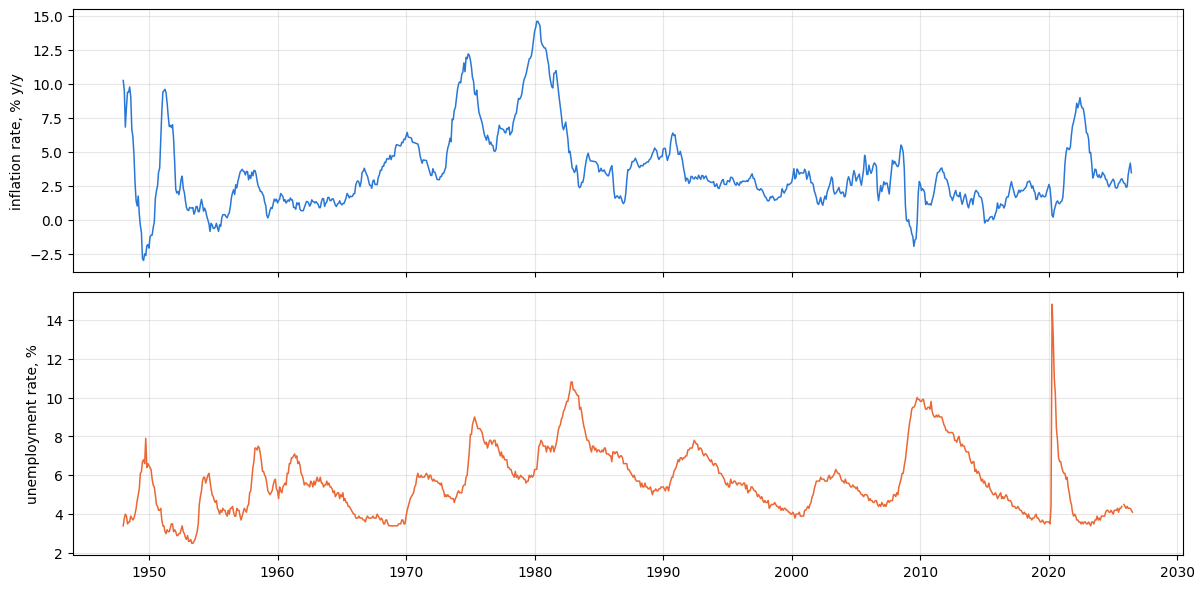

In [56]:
from pathlib import Path

MACRO = Path("../../data/TSs_macro")
cpi = pd.read_csv(MACRO / "CPIAUCSL.csv", parse_dates=["Date"]).set_index("Date")["value"]
real_inflation = cpi.pct_change(12, fill_method=None).mul(100).dropna()
real_unemployment = pd.read_csv(MACRO / "UNRATE.csv", parse_dates=["Date"]).set_index("Date")["value"]

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(real_inflation.index, real_inflation.values, color="#2a78d6", lw=1.1)
axes[0].set_ylabel("inflation rate, % y/y")
axes[1].plot(real_unemployment.index, real_unemployment.values, color="#eb6834", lw=1.1)
axes[1].set_ylabel("unemployment rate, %")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Test samples

In [ ]:
"""
Synthetic TREND + WHITE NOISE of the US inflation rate and the US unemployment
rate, 1970-2025.

Only the long-run trend plus white noise is simulated: no structural
breaks, no business cycles. Each series is

    x_t = trend(t) + eps_m(t),     eps_m ~ N(0, sigma^2)  i.i.d. per MONTH

Like the real (monthly published) statistics, the noise changes only once
per month: one draw per calendar month, held constant over all trading days
of that month (step function). The trend itself is still smooth daily.

where trend(t) is a smooth, asymmetric main hump (the 1970s/80s inflation
wave) plus a few slow, wide Gaussian bumps for the long-run swings after it:

    trend(t) = hump(t) + sum_k a_k * exp(-0.5 * ((t - c_k) / s_k)^2)

hump(t) in percent:

    x(t) = L_up   + (P - L_up)   * exp(-0.5 * ((t - t_peak) / w_up)^2)     for t <  t_peak
    x(t) = L_down + (P - L_down) * exp(-0.5 * ((t - t_peak) / w_down)^2)   for t >= t_peak

    t       years since 1970-01-01
    P       level at the peak (in %)
    t_peak  time of the peak
    L_up    level the rising side starts from, w_up its width (slow rise)
    L_down  long-run level after the peak, w_down its width (fall after the peak)

    a_k     height of bump k (pp, negative = dip), c_k its centre (years
            since 1970), s_k its width (years, >= 1.5 -> no short spikes)

Inflation: rises slowly from ~4 % (1970) to ~10 % (late 1980), falls back
quickly, then: bump ~1990 (+2.2 pp), long low phase ~2010-2020 (-1.3 pp),
bump ~2022 (+3.1 pp); long-run level ~2.6 %.
Unemployment: rises from ~4.5 % (1970) to ~8 % (1984), falls back, then:
bump ~1992 (+2.1 pp), bump ~2011 (+4.3 pp, Great Recession), dip ~2024
(-1.1 pp); long-run level ~4.9 %. Short cycles and spikes (e.g. COVID 2020)
are deliberately NOT modelled - only the slow trend.

Parameters: least-squares fit of trend(t) to the 3-year centred moving average
of the real monthly series 1970-2025 (FRED CPIAUCSL -> 12-month % change,
UNRATE; files data/TSs_macro/CPIAUCSL.csv and UNRATE.csv). RMSE against the
moving average: 0.63 pp (inflation), 0.47 pp (unemployment); against the raw
monthly series: 1.47 pp / 1.01 pp.

Noise level sigma: robust std (MAD) of the month-to-month changes of the real
series divided by sqrt(2) (for white noise, Var(x_t - x_t-1) = 2 sigma^2):
0.22 pp (inflation), 0.10 pp (unemployment). The two noises are independent.
This calibration is on MONTHLY changes, which matches the monthly noise.

The output keeps the columns of the previous price simulation (price,
log_price, dev, is_break) so that the sanity checks in section 5 keep working;
dev and is_break are 0 everywhere because there are no breaks.
`seed` drives the noise -> fully reproducible. The noise-free trend is saved
as well (columns inflation_trend, unemployment_trend).
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"

# Trend parameters (fitted, see docstring)
# main hump
TREND_INFLATION    = dict(L_up=4.00, L_down=2.62, P=10.18, t_peak=10.91, w_up=5.20, w_down=1.55)
TREND_UNEMPLOYMENT = dict(L_up=3.62, L_down=4.93, P=8.13,  t_peak=14.03, w_up=8.88, w_down=2.33)
# slow bumps (a_k [pp], c_k [years since 1970], s_k [years])
BUMPS_INFLATION    = [( 2.21, 20.00, 1.80),   # ~1990
                      (-1.28, 45.98, 4.03),   # ~2016, long low-inflation phase
                      ( 3.06, 52.52, 1.50)]   # ~2022
BUMPS_UNEMPLOYMENT = [( 2.10, 22.73, 1.82),   # ~1992
                      ( 4.31, 41.15, 1.94),   # ~2011, Great Recession
                      (-1.08, 54.41, 1.50)]   # ~2024

# White-noise standard deviations in percentage points, one draw per month (see docstring)
SIGMA_INFLATION, SIGMA_UNEMPLOYMENT = 0.22, 0.10

OUT_DIR   = "../data/stock_prices/full_series"
REAL_DIR  = "../../data/TSs_macro"   # only used for the comparison plot

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0          # trading-day clock, as in the other cells
T_CAL = ((DATES - pd.Timestamp(START)).days / 365.25).to_numpy()   # calendar years for the trend
MONTH_ID = ((DATES.year - DATES[0].year) * 12 + DATES.month - DATES[0].month).to_numpy()  # 0, 1, 2, ... per calendar month
N_MONTHS = int(MONTH_ID.max()) + 1


def hump_trend(t: np.ndarray, L_up: float, L_down: float, P: float,
               t_peak: float, w_up: float, w_down: float) -> np.ndarray:
    """Asymmetric hump: rises from L_up to P at t_peak, then falls to L_down."""
    t = np.asarray(t, dtype=float)
    rising = t < t_peak
    g = np.exp(-0.5 * ((t - t_peak) / np.where(rising, w_up, w_down)) ** 2)
    return np.where(rising, L_up + (P - L_up) * g, L_down + (P - L_down) * g)


def long_run_trend(t: np.ndarray, hump: dict, bumps: list) -> np.ndarray:
    """Main hump plus slow Gaussian bumps."""
    t = np.asarray(t, dtype=float)
    y = hump_trend(t, **hump)
    for a, c, s in bumps:
        y = y + a * np.exp(-0.5 * ((t - c) / s) ** 2)
    return y


def simulate(seed: int = 7) -> dict:
    """Trend + monthly white noise (one draw per month, held over its trading days); `seed` fixes the noise."""
    rng = np.random.default_rng(seed)
    trend_inflation    = long_run_trend(T_CAL, TREND_INFLATION,    BUMPS_INFLATION)
    trend_unemployment = long_run_trend(T_CAL, TREND_UNEMPLOYMENT, BUMPS_UNEMPLOYMENT)
    noise_inflation    = rng.normal(0.0, SIGMA_INFLATION,    size=N_MONTHS)[MONTH_ID]
    noise_unemployment = rng.normal(0.0, SIGMA_UNEMPLOYMENT, size=N_MONTHS)[MONTH_ID]
    price_inflation    = trend_inflation    + noise_inflation
    price_unemployment = trend_unemployment + noise_unemployment
    return {
        "seed":               seed,
        "n_struc":            0,
        "t_struc":            np.array([], dtype=int),
        "trend_inflation":    trend_inflation,
        "trend_unemployment": trend_unemployment,
        "price_inflation":    price_inflation,
        "price_unemployment": price_unemployment,
        # rates stay > 0 here (trend >= ~1.3 %, sigma 0.22); guarded anyway
        "logp_inflation":     np.log(np.where(price_inflation > 0, price_inflation, np.nan)),
        "logp_unemployment":  np.log(np.where(price_unemployment > 0, price_unemployment, np.nan)),
        "dev_inflation":      np.zeros(N),
        "dev_unemployment":   np.zeros(N),
    }


def report(result: dict) -> None:
    print(f"n = {N} trading days  ({START} to {END},  ~{N/252:.1f} years)  - trend + monthly white noise")
    for name, p in (("inflation", TREND_INFLATION), ("unemployment", TREND_UNEMPLOYMENT)):
        x = result[f"trend_{name}"]
        i_peak = int(np.argmax(x))
        noise = result[f"price_{name}"] - x
        print(f"  {name:12s}: trend 1970 = {x[0]:5.2f} %   peak = {x[i_peak]:5.2f} % on {DATES[i_peak].date()}   "
              f"2025 = {x[-1]:5.2f} %   noise std = {noise.std():.3f} pp ({N_MONTHS} monthly draws)")


def to_dataframe(result: dict) -> pd.DataFrame:
    return pd.DataFrame({
        "date":                   DATES,
        "t_years":                T,
        "inflation_price":        result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":    result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":          result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":               np.zeros(N, dtype=int),
        "inflation_trend":        result["trend_inflation"],
        "unemployment_trend":     result["trend_unemployment"],
    })


def _load_real():
    """Real monthly series for the comparison plot (None if the files are missing)."""
    try:
        cpi = pd.read_csv(os.path.join(REAL_DIR, "CPIAUCSL.csv"), parse_dates=["Date"]).set_index("Date")["value"].dropna()
        un  = pd.read_csv(os.path.join(REAL_DIR, "UNRATE.csv"),   parse_dates=["Date"]).set_index("Date")["value"].dropna()
    except FileNotFoundError:
        return None
    return {"inflation": (cpi.pct_change(12, fill_method=None) * 100).dropna()[START:END], "unemployment": un[START:END]}


if __name__ == "__main__":
    SEED = 7

    os.makedirs(OUT_DIR, exist_ok=True)

    result = simulate(SEED)
    report(result)

    df       = to_dataframe(result)
    csv_path = os.path.join(OUT_DIR, f"full_baseline_inflation_unemployment_trial_seed{SEED}.csv")
    df.to_csv(csv_path, index=False)
    print(f"\nData saved: {csv_path}")
    # copy used as the GIVEN trial dataset by the sanity checks (section 5)
    df.to_csv(os.path.join(os.path.dirname(OUT_DIR), f"baseline_inflation_unemployment_trial_seed{SEED}.csv"), index=False)

    # ── Plot: real series (thin, grey) vs simulated trend ─────────────
    real = _load_real()
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for ax, name, color, ylabel in ((axes[0], "inflation",    "#2a78d6", "inflation rate, % y/y"),
                                    (axes[1], "unemployment", "#eb6834", "unemployment rate, %")):
        if real is not None:
            ax.plot(real[name].index, real[name].values, color="#b5b4af", lw=0.9, label="real (FRED)")
        ax.plot(DATES, result[f"price_{name}"], color=color, lw=0.8, alpha=0.7, label="simulated (trend + monthly noise)")
        ax.plot(DATES, result[f"trend_{name}"], color=color, lw=2.0, label="trend")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, loc="upper right")
    axes[1].xaxis.set_major_locator(mdates.YearLocator(5))
    axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    axes[0].set_title("Synthetic trend of inflation and unemployment 1970-2025 (trend + monthly white noise, no breaks)", loc="left")
    plt.tight_layout()
    plt.show()

## 4. Sample baseline TSs

### 4.1 Sampling of structural breaks with different sizes of magnitudes

In [58]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
STRUCTURAL BREAK simulation.

PRICE MODEL (rates in percent):
  x_t = trend_t + noise_t + dev_t
  trend_t + noise_t is the baseline from "3. Test samples" (loaded from
  baseline_inflation_unemployment_trial_seed7.csv). dev_t is a structural
  break inside each window: a jump of size MAG_CATEGORIES[cat] (pp, random
  sign) at the window start that decays linearly to 0 at the window end.
  Unemployment's break = BETA_UNEMPLOYMENT * inflation's break + noise.
  Outside the windows dev_t = 0 -> identical to the baseline.

Each CSV contains 5000 rows:
  - 2500 outside a break window (evenly spaced dates)
  - 2500 inside a break window (each window's own sample count
    proportional to its LENGTH, dates within a window drawn from a
    truncated power-law/Zipf profile)

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a break window this is Zipf-shaped and inflation-dominant
       (decaying but always largest; unemployment decays faster); outside any
       break window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev counterparts) are
  populated ONLY when that commodity was actually sampled as a topic
  for that row -- e.g. if "inflation" is not in commodity_topics, price_inflation
  is None, even though inflation's underlying price series was simulated
  for every date.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_struct_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_struct_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"


H_MIN, H_MAX = 60, 750

# Break size of INFLATION at the window start, in percentage points
# (sign random); the break decays linearly to 0 over the window.
# For scale: base noise sigma ~0.22 pp, trend range ~1.3-10 %.
MAG_CATEGORIES = {
    "low":    (0.5, 1.0),
    "medium": (1.0, 2.0),
    "high":   (2.0, 3.5),
}

# Unemployment break = BETA * inflation break + N(0, MAG_NOISE) (pp)
BETA_UNEMPLOYMENT = 0.5
MAG_NOISE   = 0.10
BUFFER_DAYS = 20   # minimum gap enforced between consecutive break windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

# ── Baseline = output of the simulation under "3. Test samples" ─────
# (smooth long-run trend + i.i.d. white noise, in percent). It is the
# single source of truth: every generator below only ADDS its effect
# inside the windows, so all "out" dates are identical to this baseline.
BASELINE_PATH = os.path.join(OUT_DIR, f"baseline_inflation_unemployment_trial_seed{SEED}.csv")
_base = pd.read_csv(BASELINE_PATH, parse_dates=["date"])
assert len(_base) == N and (_base["date"].to_numpy() == DATES.to_numpy()).all(), \
    "baseline file does not match DATES -- re-run the cell under '3. Test samples' first"
TREND_INFLATION    = _base["inflation_trend"].to_numpy()
TREND_UNEMPLOYMENT = _base["unemployment_trend"].to_numpy()
NOISE_INFLATION    = _base["inflation_price"].to_numpy()    - TREND_INFLATION
NOISE_UNEMPLOYMENT = _base["unemployment_price"].to_numpy() - TREND_UNEMPLOYMENT
SIGMA_INFLATION    = float(NOISE_INFLATION.std())      # ~0.22 pp
SIGMA_UNEMPLOYMENT = float(NOISE_UNEMPLOYMENT.std())   # ~0.10 pp


def safe_log(x) -> np.ndarray:
    """log of a rate; NaN where the rate is <= 0 (e.g. deflation)."""
    x = np.asarray(x, dtype=float)
    return np.log(np.where(x > 0, x, np.nan))



# ══════════════════════════════════════════════════════════════════
# Commodity topic selection (merged from commodity_sampling.py)
# ══════════════════════════════════════════════════════════════════
import numpy as np

# ── Configuration ───────────────────────────────────────────────────
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """
    Truncated Zipf (power-law) decay shape, rescaled to [0, 1].

        w(k) = k^(-alpha) / max_k(k^(-alpha))      for k = 1..n_years

    This is the same power-law functional form (k^-alpha) used in
    zipf_window_weights for article-date sampling within break/spike
    windows -- just rescaled here (divided by its max instead of its
    sum) so the resulting curve can be combined with an additive
    floor + scale to compete against other categories' weights.
    """
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True  (default): time-varying distribution based on t_years
                 (years since simulation start). Used for observations
                 that fall WITHIN a structural-break / volatility-spike
                 recovery window -- this is when heightened, skewed
                 commodity attention (inflation-dominant, decaying over time)
                 makes narrative sense.
    inside=False: UNIFORM distribution -- all four commodities equally
                 likely (25% each), no Zipf/power-law shaping at all.
                 Used for observations OUTSIDE any break window, where
                 there's no reason for one commodity to be structurally
                 more newsworthy than another.

    Guarantees (verified for all t in [0, N_YEARS-1], both inside modes):
      - all four probabilities are >= 0 and sum to exactly 1.0
      - when inside=True: "inflation" is always the single largest probability
      - when inside=False: all four are exactly equal (0.25 each)
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    # ── correctness guarantees ──────────────────────────────────────
    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """
    Sample one commodity name.

    inside=True  -> time-varying Zipf-shaped distribution (see commodity_probs)
    inside=False -> uniform distribution over all four commodities
    """
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support (not a naive sample-then-clip shortcut -- see
    project notes on truncated vs. naively-capped Poisson).

    lam=1.2 -> most articles cover 1 commodity, a meaningful minority
    cover 2, rarely 3+.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))
def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).

    VERBATIM from the struct/var dataset-builder scripts -- this is
    the confirmed, non-speculative implementation (previously this
    function had to be reconstructed by guesswork; that guess is now
    replaced with the real thing, including the final sort() step).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())


# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, category: str) -> dict:
    """
    Baseline (trend + white noise) plus structural breaks whose size is
    drawn from MAG_CATEGORIES[category] (percentage points). The window
    placement uses the same RNG draws as before, so windows are identical
    across low/medium/high, var, rho and the baseline builder.
    """
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    # Enforce minimum gap + buffer between windows so each effect
    # genuinely decays to zero before the next window starts.
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    signs          = rng.choice([-1, 1], size=n_struc)
    mag_lo, mag_hi = MAG_CATEGORIES[category]
    mags_inflation    = signs * rng.uniform(mag_lo, mag_hi, size=n_struc)
    mags_unemployment = BETA_UNEMPLOYMENT * mags_inflation + rng.normal(scale=MAG_NOISE, size=n_struc)

    dev_inflation    = np.zeros(N)
    dev_unemployment = np.zeros(N)
    inside_mask      = np.zeros(N, dtype=bool)
    for bp, mg, ms, h_j in zip(t_struc, mags_inflation, mags_unemployment, h_js):
        end_i = min(bp + h_j, N)
        inside_mask[bp:end_i] = True
        frac = 1 - (np.arange(bp, end_i) - bp) / h_j      # jump at bp, linear decay to 0
        dev_inflation[bp:end_i]    += mg * frac
        dev_unemployment[bp:end_i] += ms * frac

    price_inflation    = TREND_INFLATION    + NOISE_INFLATION    + dev_inflation
    price_unemployment = TREND_UNEMPLOYMENT + NOISE_UNEMPLOYMENT + dev_unemployment

    return {
        "inside_mask":        inside_mask,
        "inside_windows":     list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_break_mags":  np.abs(mags_inflation).tolist(),  # break size per window (pp)
        "dev_inflation":      dev_inflation,
        "dev_unemployment":   dev_unemployment,
        "logp_inflation":     safe_log(price_inflation),
        "logp_unemployment":  safe_log(price_unemployment),
        "price_inflation":    price_inflation,
        "price_unemployment": price_unemployment,
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

        P(k) = k^(-alpha) / sum_{j=1}^{length} j^(-alpha)      for k=1..length

    Used instead of a geometric/exponential decay because empirical
    studies of post-shock financial time series find that volatility
    and volume decay as a POWER LAW, not exponentially, after a market
    shock — i.e. effects persist much longer into the recovery window
    than a geometric distribution would predict.

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696
      -> empirically estimated power-law decay exponents for post-event
         excess volatility/volume of ~0.25-0.35 on NYSE and ~0.35-0.40
         on NASDAQ; 0.3 sits at the NYSE estimate, used here as a
         literature-grounded middle-of-the-road default.

    The truncated (finite-support) Zipf distribution used here follows
    the formal treatment in:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH (in days) relative to the total inside-day count — no
    magnitude weighting, no global pooled/renormalized draw.

    Within each window, the specific dates are drawn using a truncated
    power-law (Zipf, alpha) profile — same functional form as before,
    just applied independently per window instead of via a global pool.
    """
    windows        = result["inside_windows"]
    lengths        = np.array([e - s for s, e in windows])
    total_days     = lengths.sum()

    # quota per window, proportional to its own length
    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)  # can't draw more than the window holds

    # fix any rounding drift so quotas sum exactly to n_total
    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)  # adjust largest windows first
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three categories ─────────────────────────────────
print("Simulating all three categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium — check RNG consumption order."
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high — check RNG consumption order."

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
# 2500 outside dates, evenly spaced across the outside range
outside_sample_idx = even_sample(outside_idx, 2500)

# 2500 inside dates, with each window's own count proportional to its
# LENGTH (independently, not via a global pool/fixed group split),
# dates within each window drawn from a Zipf power-law profile
inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# Re-seeded IDENTICALLY inside the loop for each category so
# commodity_topics is the same across low/medium/high — only the
# price magnitude differs, not which commodities are discussed.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per category ─────────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    # ── one wide row per obs_id — price data ONLY present for
    # commodities that were actually SAMPLED as topics for that row.
    # E.g. if "inflation" is not among the sampled topics, price_inflation is None.
    for obs_id, idx in enumerate(sample_idx):
        topics    = sample_commodities(commodity_topic_rng, T[idx],
                                       inside=bool(result["inside_mask"][idx]))
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]   if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]    if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]     if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx] if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]  if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]   if has_unemployment else None,
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_struct_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside      = (df_out["label"] == 1).sum()
    n_outside     = (df_out["label"] == 0).sum()
    topic_counts  = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")


Simulating all three categories...
Break structure: 7174 outside days, 7436 inside days (out of 14610 total)
Sampled 2500 outside + 2500 inside = 5000 total dates
[low   ]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}
[medium]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_struct_medium_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}
[high  ]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_struct_high_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}

Done.


In [59]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_struct_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



[low   ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_struct_low_seed7.csv
[medium]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_struct_medium_seed7.csv
[high  ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_struct_high_seed7.csv


Found 17 break windows


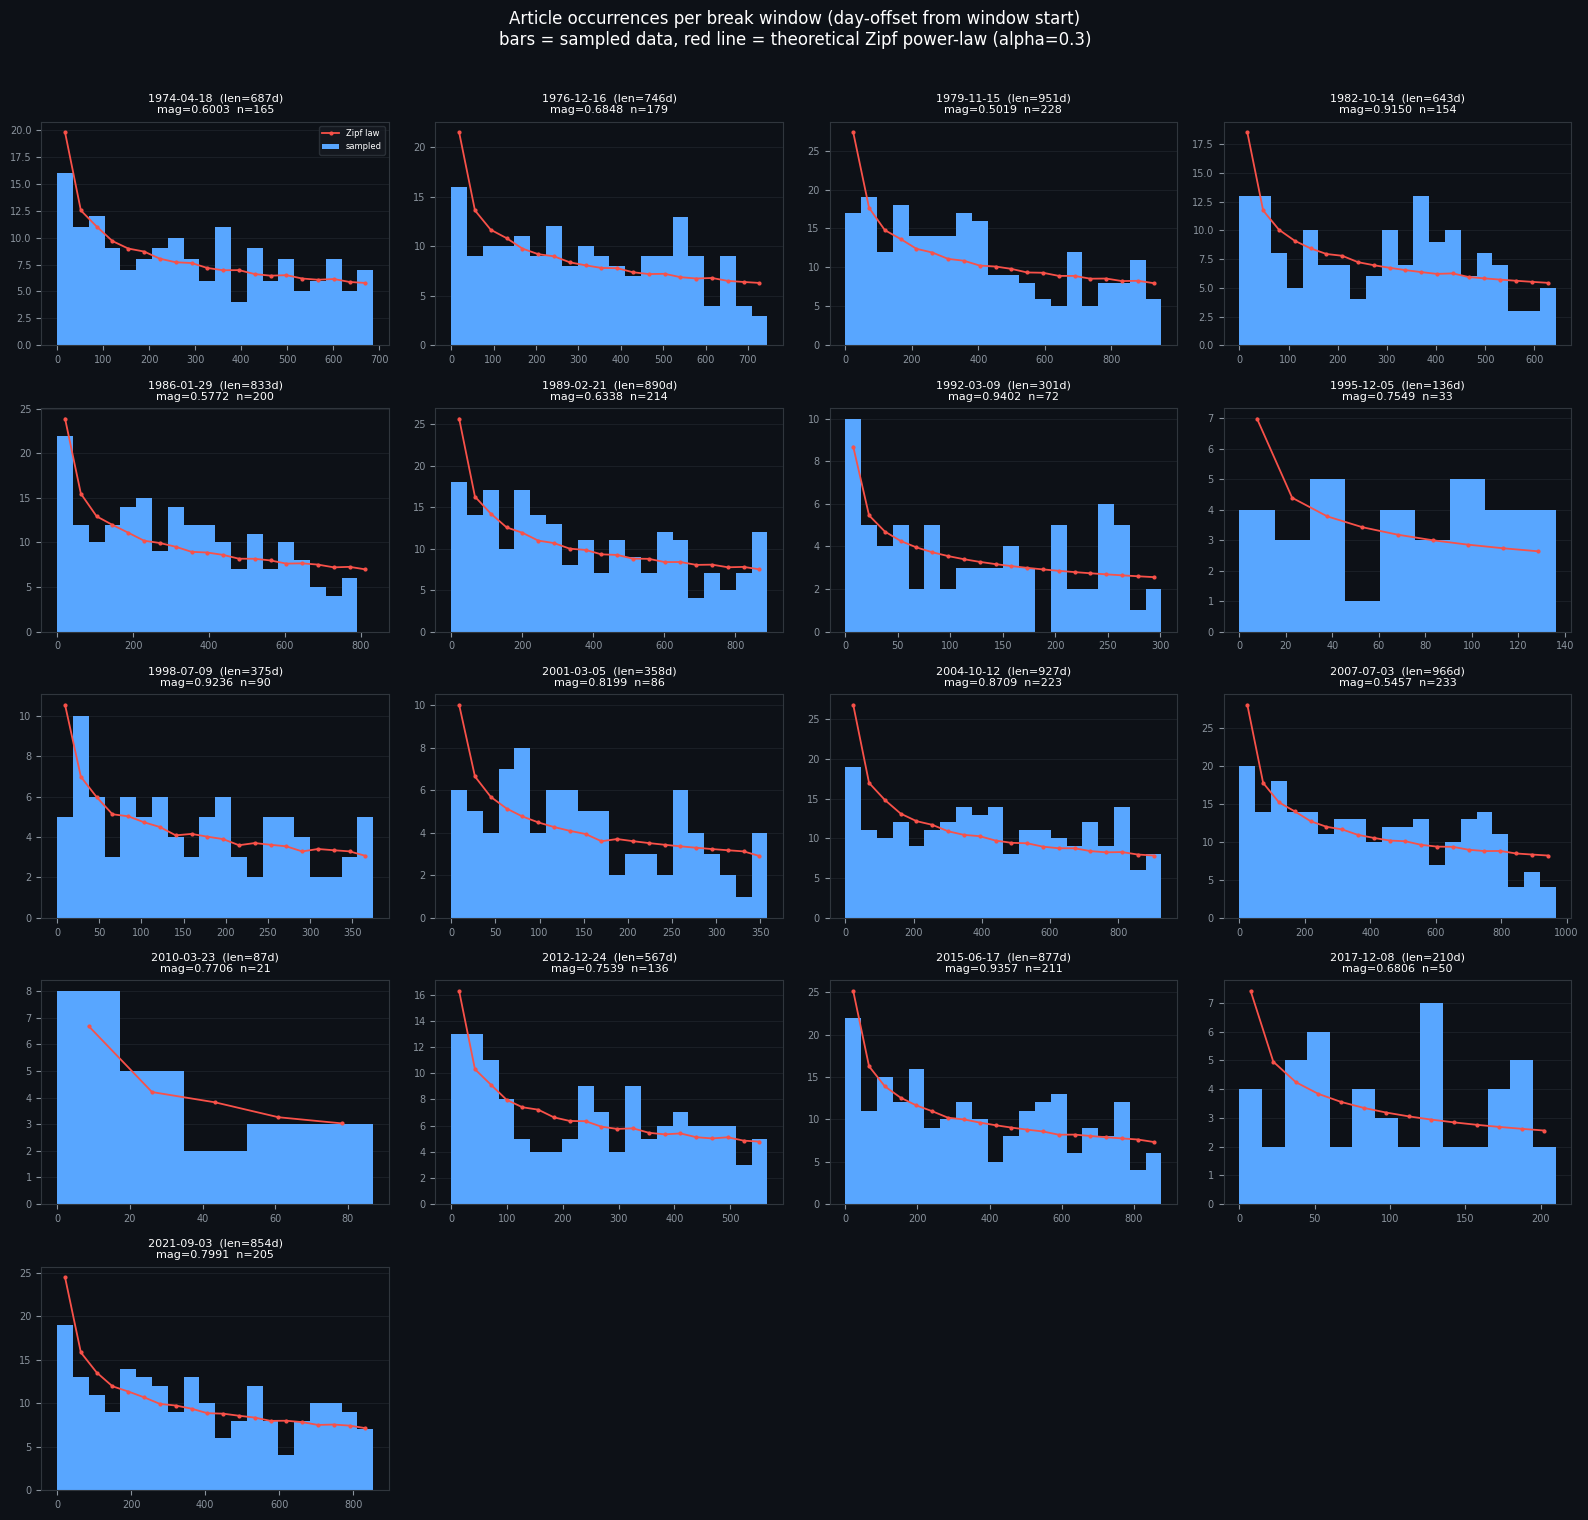

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Re-run simulate() in-memory instead of loading a baseline CSV ──
result_low = simulate(SEED, "low")
DATES_arr  = DATES

# ── Load the already-sampled final dataset ──────────────────────────
final = pd.read_csv("../data/stock_prices/articles_inflation_unemployment_struct_low_seed7.csv",
                     parse_dates=["date"])

# ── Use inside_windows and window_break_mags directly from simulate() ──
windows = [
    (DATES_arr[s], DATES_arr[min(e, len(DATES_arr) - 1)], mag)
    for (s, e), mag in zip(result_low["inside_windows"], result_low["window_break_mags"])
]
print(f"Found {len(windows)} break windows")

# ── Build a grid of subplots, one per window ────────────────────────
n_windows = len(windows)
n_cols    = 4
n_rows    = int(np.ceil(n_windows / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                          facecolor="#0d1117")
axes = axes.flatten()

for i, (start_date, end_date, mag) in enumerate(windows):
    ax     = axes[i]
    mask   = (final["date"] >= start_date) & (final["date"] < end_date)
    offsets = (final.loc[mask, "date"] - start_date).dt.days
    length  = (end_date - start_date).days
    n_here  = len(offsets)

    ax.set_facecolor("#0d1117")
    if n_here > 0:
        n_bins = max(5, min(20, length // 15))
        counts, edges = np.histogram(offsets, bins=n_bins, range=(0, length))
        ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
               color="#58a6ff", edgecolor="none", label="sampled")

        # ── theoretical Zipf law, scaled to this window's n_here ──
        theo_weights = zipf_window_weights(length, alpha=ZIPF_ALPHA)  # per single day
        # expected count per histogram bin = n_here * sum(theo_weights in that bin range)
        bin_idx      = np.digitize(np.arange(length), edges[1:-1])
        expected     = np.array([theo_weights[bin_idx == b].sum() * n_here
                                  for b in range(len(edges) - 1)])
        bin_centers  = (edges[:-1] + edges[1:]) / 2
        ax.plot(bin_centers, expected, color="#f85149", lw=1.3,
                marker="o", markersize=2, label="Zipf law")

    ax.set_title(f"{start_date.date()}  (len={length}d)\n"
                 f"mag={mag:.4f}  n={n_here}",
                 color="white", fontsize=8)
    ax.tick_params(colors="#8b949e", labelsize=7)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d",
                  labelcolor="white", fontsize=6, loc="upper right")

for j in range(n_windows, len(axes)):
    axes[j].axis("off")

fig.suptitle("Article occurrences per break window (day-offset from window start)\n"
             "bars = sampled data, red line = theoretical Zipf power-law "
             f"(alpha={ZIPF_ALPHA})",
             color="white", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

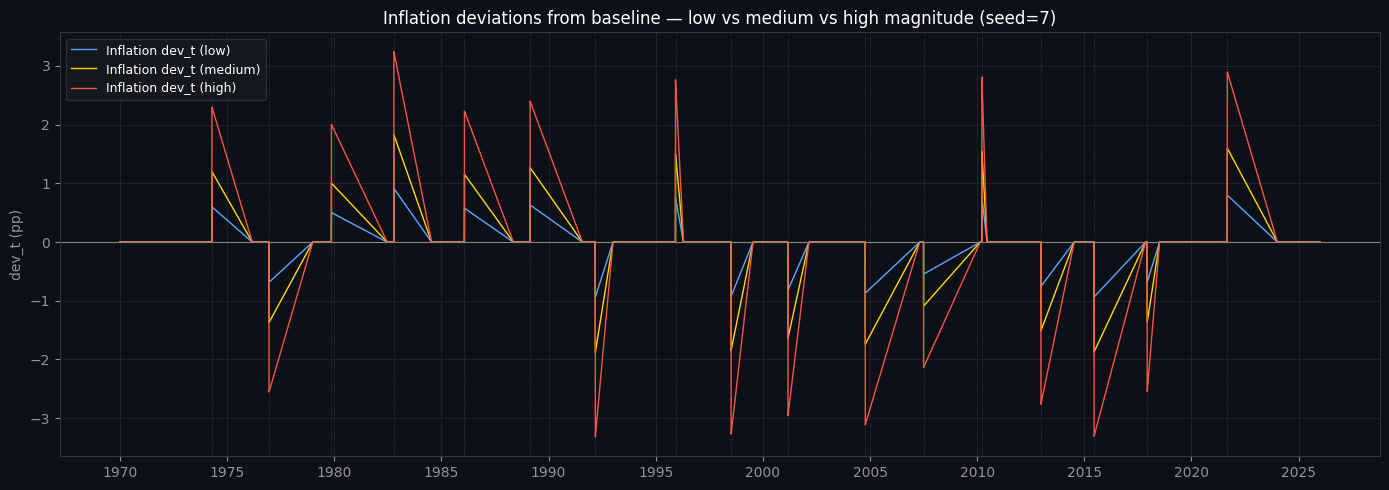

In [61]:
import matplotlib.dates as mdates
cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Additional plot: inflation deviations across all three categories ──
fig2, ax = plt.subplots(figsize=(14, 5), facecolor="#0d1117")
ax.set_facecolor("#0d1117")
for cat in ("low", "medium", "high"):
    ax.plot(DATES, results[cat]["dev_inflation"],
            color=cat_colors[cat], lw=1.0, label=f"Inflation dev_t ({cat})")
ax.axhline(0, color="#888780", lw=0.8)
for start_i, end_i in results["low"]["inside_windows"]:
    ax.axvline(DATES[start_i], color="#888780", ls=":", lw=0.5, alpha=0.5)
ax.set_title("Inflation deviations from baseline — low vs medium vs high magnitude (seed=7)",
                color="white", fontsize=12)
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.set_ylabel("dev_t (pp)", color="#8b949e")
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 4.2 Sampling labels for baseline all commodities

In [62]:
"""
Builds the BASELINE dataset for both series (inflation, unemployment):
no structural break, no extra variance, no extra correlation.

  - OUT rows (label 0): dates + topic labels reused from the reference
    struct dataset (identical across struct/var, low/medium/high).
  - IN rows (label 1): 2500 dates sampled uniformly at random from the
    same break windows, topic labels via sample_commodities.
  - Prices: the baseline series (trend + white noise) written by the
    simulation under "3. Test samples"
    (baseline_inflation_unemployment_trial_seed7.csv), so dev_* = 0.

Needs: the simulation cell (section 3) and section 4.1 (struct) to have
run before.
"""

import os
import numpy as np
import pandas as pd
from scipy.stats import poisson

DATA_DIR    = "../data/stock_prices"
N_IN        = 2500
COMMODITIES = ["inflation", "unemployment"]

# ── Constants required by build_inside_mask ──────────────────────────
H_MIN, H_MAX = 60, 750
BUFFER_DAYS  = 20

# ── Constants required by commodity_probs / build_shape ─────────────
# Taken verbatim from the struct dataset-builder script.
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


# ── SEED / DATES / T -- taken verbatim from the struct dataset-builder
#    script so IN/OUT dates and topic sampling line up exactly with the
#    reference dataset. ────────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"
SEED  = 7

DATES = pd.bdate_range(START, END)
T     = np.arange(len(DATES)) / 252.0


# ══════════════════════════════════════════════════════════════════
# Transferred helper functions (verbatim from the struct dataset-
# builder script -- the confirmed source of `sample_commodities`)
# ══════════════════════════════════════════════════════════════════

def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """
    Truncated Zipf (power-law) decay shape, rescaled to [0, 1].

        w(k) = k^(-alpha) / max_k(k^(-alpha))      for k = 1..n_years
    """
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


# Shapes needed by commodity_probs -- built once at import time.
# NOTE: inflation and unemployment use DIFFERENT alphas (INFLATION_ALPHA vs UNEMPLOYMENT_ALPHA),
# unlike the earlier placeholder version which used the same ZIPF_ALPHA
# for both. This matches the verbatim source exactly.
inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """
    Sample one commodity name.
    """
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    """
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).

    VERBATIM from the struct/var dataset-builder scripts -- this is
    the confirmed, non-speculative implementation (previously this
    function had to be reconstructed by guesswork; that guess is now
    replaced with the real thing, including the final sort() step).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())


def build_inside_mask(seed: int, n_dates: int) -> np.ndarray:
    """
    Reconstructs the boolean 'inside a structural break window' mask
    for a date series, without depending on the notebook's ambiguous
    global `simulate`.
    """
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (n_dates - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, n_dates - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    mask = np.zeros(n_dates, dtype=bool)
    for bp, h_j in zip(t_struc, h_js):
        mask[bp: min(bp + h_j, n_dates)] = True
    return mask


# ══════════════════════════════════════════════════════════════════
# Main script logic (unchanged from the original)
# ══════════════════════════════════════════════════════════════════

# ── 1. OUT rows: dates + topic labels reused from the reference
#    struct dataset (identical across struct/var, low/medium/high) ──
REFERENCE_PATH = os.path.join(
    DATA_DIR, f"articles_inflation_unemployment_struct_low_seed{SEED}.csv"
)
reference = pd.read_csv(REFERENCE_PATH, parse_dates=["date"])

out_meta = reference.loc[
    reference["label"] == 0,
    ["date", "t_years", "inflation", "unemployment", "commodity_topics"],
].copy()
out_meta["label"] = 0
out_meta["IN"]    = 0

# ── 2. IN dates: sampled UNIFORMLY AT RANDOM across the break-window
#    period, topic labels via sample_commodities -- same mechanism as
#    the earlier baseline used earlier ────────────────────────────
inside_mask = build_inside_mask(SEED, len(DATES))
inside_idx  = np.where(inside_mask)[0]

in_date_rng   = np.random.default_rng(SEED + 2)
in_sample_idx = np.sort(in_date_rng.choice(inside_idx, size=N_IN, replace=False))
print(f"Sampled {len(in_sample_idx)} IN dates uniformly at random from "
      f"{len(inside_idx)} total in-window days.")

commodity_topic_rng = np.random.default_rng(SEED + 4)
in_meta = []
for idx in in_sample_idx:
    topics = sample_commodities(commodity_topic_rng, T[idx], inside=True)
    in_meta.append({
        "date":             DATES[idx],
        "t_years":          T[idx],
        "inflation":             int("inflation" in topics),
        "unemployment":           int("unemployment" in topics),
        "commodity_topics": ",".join(topics),
        "label":            1,
        "IN":               1,
    })
in_meta = pd.DataFrame(in_meta)

# ── 3. Combine OUT + IN metadata (dates + topic labels only, no
#    prices yet) ──────────────────────────────────────────────────────
meta = pd.concat([out_meta, in_meta], ignore_index=True)
meta = meta.sort_values("date").reset_index(drop=True)

# ── 4. Attach the prices of both series: the baseline (trend + white
#    noise) written by the simulation under "3. Test samples" ───────────
ALL_COMMODITIES_PATH = os.path.join(DATA_DIR, f"baseline_inflation_unemployment_trial_seed{SEED}.csv")
prices = (pd.read_csv(ALL_COMMODITIES_PATH, parse_dates=["date"])
          .rename(columns={f"{c}_price": f"price_{c}" for c in COMMODITIES}))

price_cols = [f"price_{c}" for c in COMMODITIES]
missing_cols = [c for c in price_cols if c not in prices.columns]
if missing_cols:
    raise ValueError(f"Missing expected price columns: {missing_cols}")
prices = prices[["date"] + price_cols]

df_baseline = meta.merge(prices, on="date", how="left", validate="many_to_one")

# ── 5. Per-commodity: verify no missing prices where that commodity is
#    a topic, then null out price/log_price/dev where it's NOT a topic
#    (same multi-hot convention used throughout the rest of the pipeline) ──
for c in COMMODITIES:
    has_c     = df_baseline[c] == 1
    raw_price = df_baseline[f"price_{c}"].astype(float)

    n_missing = raw_price[has_c].isna().sum()
    if n_missing:
        raise ValueError(f"{n_missing} rows with '{c}' as a topic could not be "
                          f"matched to a price in {ALL_COMMODITIES_PATH}.")

    # rates can be <= 0 (deflation) -> log only where defined
    log_price = np.log(raw_price.where(raw_price > 0))
    df_baseline[f"price_{c}"]     = np.where(has_c, raw_price, None)
    df_baseline[f"log_price_{c}"] = np.where(has_c, log_price, None)
    df_baseline[f"dev_{c}"]       = np.where(has_c, 0.0, None)

df_baseline = df_baseline.sort_values("date").reset_index(drop=True)
df_baseline["obs_id"] = df_baseline.index

OUT_PATH = os.path.join(DATA_DIR, f"articles_all_commodities_baseline_seed{SEED}.csv")
df_baseline.to_csv(OUT_PATH, index=False)

# ── 6. Sanity checks ──────────────────────────────────────────────────
print(f"\nSaved baseline dataset: {len(df_baseline)} rows -> {OUT_PATH}")
print(f"  OUT rows: {(df_baseline['label'] == 0).sum()}  "
      f"IN rows: {(df_baseline['label'] == 1).sum()}")
for c in COMMODITIES:
    n_topic  = int(df_baseline[c].sum())
    n_priced = df_baseline[f"price_{c}"].notna().sum()
    print(f"  {c:8s}: topic count = {n_topic:5d}  price populated = {n_priced:5d}  "
          f"match = {n_topic == n_priced}")
print(f"\ncommodity_topics distribution:\n{df_baseline['commodity_topics'].value_counts()}")

Sampled 2500 IN dates uniformly at random from 7436 total in-window days.

Saved baseline dataset: 5000 rows -> ../data/stock_prices/articles_all_commodities_baseline_seed7.csv
  OUT rows: 2500  IN rows: 2500
  inflation: topic count =  3873  price populated =  3873  match = True
  unemployment: topic count =  2953  price populated =  2953  match = True

commodity_topics distribution:
commodity_topics
inflation                 2047
inflation,unemployment    1826
unemployment              1127
Name: count, dtype: int64


### 4.3 Sampling of volatility periods with different variances

In [63]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
VOLATILITY simulation.

PRICE MODEL (rates in percent):
  x_t = trend_t + noise_t + extra_sd_t * z_t
  trend_t + noise_t is the baseline from "3. Test samples". Inside each
  window an extra white noise with std extra_sd_t = k * sigma * frac_t is
  added (k from VAR_CATEGORIES[cat], frac_t = 1 at the window start,
  linear decay to 0). Outside the windows -> identical to the baseline.

Each CSV contains 5000 rows:
  - 2500 outside a volatility spike window (evenly spaced dates)
  - 2500 inside a volatility spike window (each window's own sample
    count proportional to its LENGTH, dates within a window drawn from
    a truncated power-law/Zipf profile)

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a spike window this is Zipf-shaped and inflation-dominant
       (decaying but always largest; unemployment decays faster); outside any
       spike window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev/sigma counterparts)
  are populated ONLY when that commodity was actually sampled as a
  topic for that row -- e.g. if "inflation" is not in commodity_topics,
  price_inflation is None, even though inflation's underlying price series was
  simulated for every date.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_var_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_var_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_var_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"


H_MIN, H_MAX = 60, 750

# Extra noise std at the window start as a MULTIPLE k of the base sigma
# (same k for both series); decays linearly to 0 over the window.
# Total std at the start = sqrt(1 + k^2) * sigma:
#   low ~1.4-2.2x, medium ~2.2-4.1x, high ~4.1-8.1x the normal noise.
VAR_CATEGORIES = {
    "low":    (1.0, 2.0),
    "medium": (2.0, 4.0),
    "high":   (4.0, 8.0),
}

BETA_UNEMPLOYMENT = 1.5
MAG_NOISE   = 0.05
BUFFER_DAYS = 20   # minimum gap enforced between consecutive spike windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

# ── Baseline = output of the simulation under "3. Test samples" ─────
# (smooth long-run trend + i.i.d. white noise, in percent). It is the
# single source of truth: every generator below only ADDS its effect
# inside the windows, so all "out" dates are identical to this baseline.
BASELINE_PATH = os.path.join(OUT_DIR, f"baseline_inflation_unemployment_trial_seed{SEED}.csv")
_base = pd.read_csv(BASELINE_PATH, parse_dates=["date"])
assert len(_base) == N and (_base["date"].to_numpy() == DATES.to_numpy()).all(), \
    "baseline file does not match DATES -- re-run the cell under '3. Test samples' first"
TREND_INFLATION    = _base["inflation_trend"].to_numpy()
TREND_UNEMPLOYMENT = _base["unemployment_trend"].to_numpy()
NOISE_INFLATION    = _base["inflation_price"].to_numpy()    - TREND_INFLATION
NOISE_UNEMPLOYMENT = _base["unemployment_price"].to_numpy() - TREND_UNEMPLOYMENT
SIGMA_INFLATION    = float(NOISE_INFLATION.std())      # ~0.22 pp
SIGMA_UNEMPLOYMENT = float(NOISE_UNEMPLOYMENT.std())   # ~0.10 pp


def safe_log(x) -> np.ndarray:
    """log of a rate; NaN where the rate is <= 0 (e.g. deflation)."""
    x = np.asarray(x, dtype=float)
    return np.log(np.where(x > 0, x, np.nan))


# ══════════════════════════════════════════════════════════════════
# Commodity topic selection
# ══════════════════════════════════════════════════════════════════
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """Truncated Zipf (power-law) decay shape, rescaled to [0, 1]."""
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True  : time-varying, Zipf-shaped, inflation-dominant distribution
                    (used INSIDE a volatility spike window)
    inside=False : uniform 25% each (used OUTSIDE any spike window)
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))

    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]

    remaining = 1.0
    gs_total  = g + s

    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }

    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"

    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True) -> str:
    """Sample one commodity name (see commodity_probs)."""
    p = commodity_probs(t_years, inside=inside)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside distribution as sample_commodity).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())
# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, var_category: str) -> dict:
    """
    Baseline (trend + white noise) plus EXTRA white noise inside the
    windows. Extra std at the window start = k * base sigma with k drawn
    from VAR_CATEGORIES[var_category]; it decays linearly to 0 over the
    window. The extra noise comes from a separate spike_rng, so outside
    the windows the series is bit-for-bit the baseline.
    """
    rng       = np.random.default_rng(seed)
    spike_rng = np.random.default_rng(seed + 1000)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    # Enforce minimum gap + buffer between windows so each effect
    # genuinely decays to zero before the next window starts.
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    dev_inflation    = np.zeros(N)
    dev_unemployment = np.zeros(N)
    inside_mask      = np.zeros(N, dtype=bool)

    z_extra_inflation    = spike_rng.normal(size=N)
    z_extra_unemployment = spike_rng.normal(size=N)
    extra_sd_inflation    = np.zeros(N)
    extra_sd_unemployment = np.zeros(N)

    k_lo, k_hi = VAR_CATEGORIES[var_category]
    window_spike_mags = []
    for bp, h_j in zip(t_struc, h_js):
        k     = spike_rng.uniform(k_lo, k_hi)
        end_i = min(bp + h_j, N)
        inside_mask[bp:end_i] = True
        frac = 1 - (np.arange(bp, end_i) - bp) / h_j
        extra_sd_inflation[bp:end_i]    = k * SIGMA_INFLATION    * frac
        extra_sd_unemployment[bp:end_i] = k * SIGMA_UNEMPLOYMENT * frac
        window_spike_mags.append(k * SIGMA_INFLATION)            # extra std at window start (pp)

    price_inflation    = TREND_INFLATION    + NOISE_INFLATION    + extra_sd_inflation    * z_extra_inflation
    price_unemployment = TREND_UNEMPLOYMENT + NOISE_UNEMPLOYMENT + extra_sd_unemployment * z_extra_unemployment

    return {
        "inside_mask":          inside_mask,
        "inside_windows":       list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_spike_mags":    window_spike_mags,
        "dev_inflation":        dev_inflation,
        "dev_unemployment":     dev_unemployment,
        # total local noise std (pp): sqrt(base^2 + extra^2)
        "sigma_inflation_t":    np.sqrt(SIGMA_INFLATION ** 2    + extra_sd_inflation ** 2),
        "sigma_unemployment_t": np.sqrt(SIGMA_UNEMPLOYMENT ** 2 + extra_sd_unemployment ** 2),
        "var_spikes":           extra_sd_inflation,
        "logp_inflation":       safe_log(price_inflation),
        "logp_unemployment":    safe_log(price_unemployment),
        "price_inflation":      price_inflation,
        "price_unemployment":   price_unemployment,
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

        P(k) = k^(-alpha) / sum_{j=1}^{length} j^(-alpha)      for k=1..length

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696

    The truncated (finite-support) Zipf distribution used here follows
    the formal treatment in:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH (in days) relative to the total inside-day count — no
    magnitude weighting, no global pooled/renormalized draw.

    Within each window, the specific dates are drawn using a truncated
    power-law (Zipf, alpha) profile.
    """
    windows    = result["inside_windows"]
    lengths    = np.array([e - s for s, e in windows])
    total_days = lengths.sum()

    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)

    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three var categories ──────────────────────────────
print("Simulating all three var categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium!"
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high!"

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
# 2500 outside dates, evenly spaced across the outside range
outside_sample_idx = even_sample(outside_idx, 2500)

# 2500 inside dates, with each window's own count proportional to its
# LENGTH, dates within each window drawn from a Zipf power-law profile
inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# Re-seeded FRESH for each category (same seed every time) so that
# commodity_topics is IDENTICAL across low/medium/high -- only the
# price magnitude/volatility differs between the three files, not
# which commodities the article discusses.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per var category ────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    # ── one wide row per obs_id — price data ONLY present for
    # commodities that were actually SAMPLED as topics for that row.
    for obs_id, idx in enumerate(sample_idx):
        topics     = sample_commodities(commodity_topic_rng, T[idx],
                                        inside=bool(result["inside_mask"][idx]))
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]     if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]      if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]       if has_inflation   else None,
            "sigma_inflation":       result["sigma_inflation_t"][idx]   if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx]   if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]    if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]     if has_unemployment else None,
            "sigma_unemployment":     result["sigma_unemployment_t"][idx] if has_unemployment else None,
            "var_spike":        result["var_spikes"][idx],
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_var_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside      = (df_out["label"] == 1).sum()
    n_outside     = (df_out["label"] == 0).sum()
    topic_counts  = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")

Simulating all three var categories...
Break structure: 7174 outside days, 7436 inside days (out of 14610 total)
Sampled 2500 outside + 2500 inside = 5000 total dates
[low   ]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_var_low_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}
[medium]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_var_medium_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}
[high  ]  5000 rows  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_var_high_seed7.csv
          commodity_topic distribution: {'inflation': 2014, 'inflation,unemployment': 1880, 'unemployment': 1106}

Done.


In [64]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_var_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



[low   ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_var_low_seed7.csv
[medium]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_var_medium_seed7.csv
[high  ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_var_high_seed7.csv


Found 17 break windows


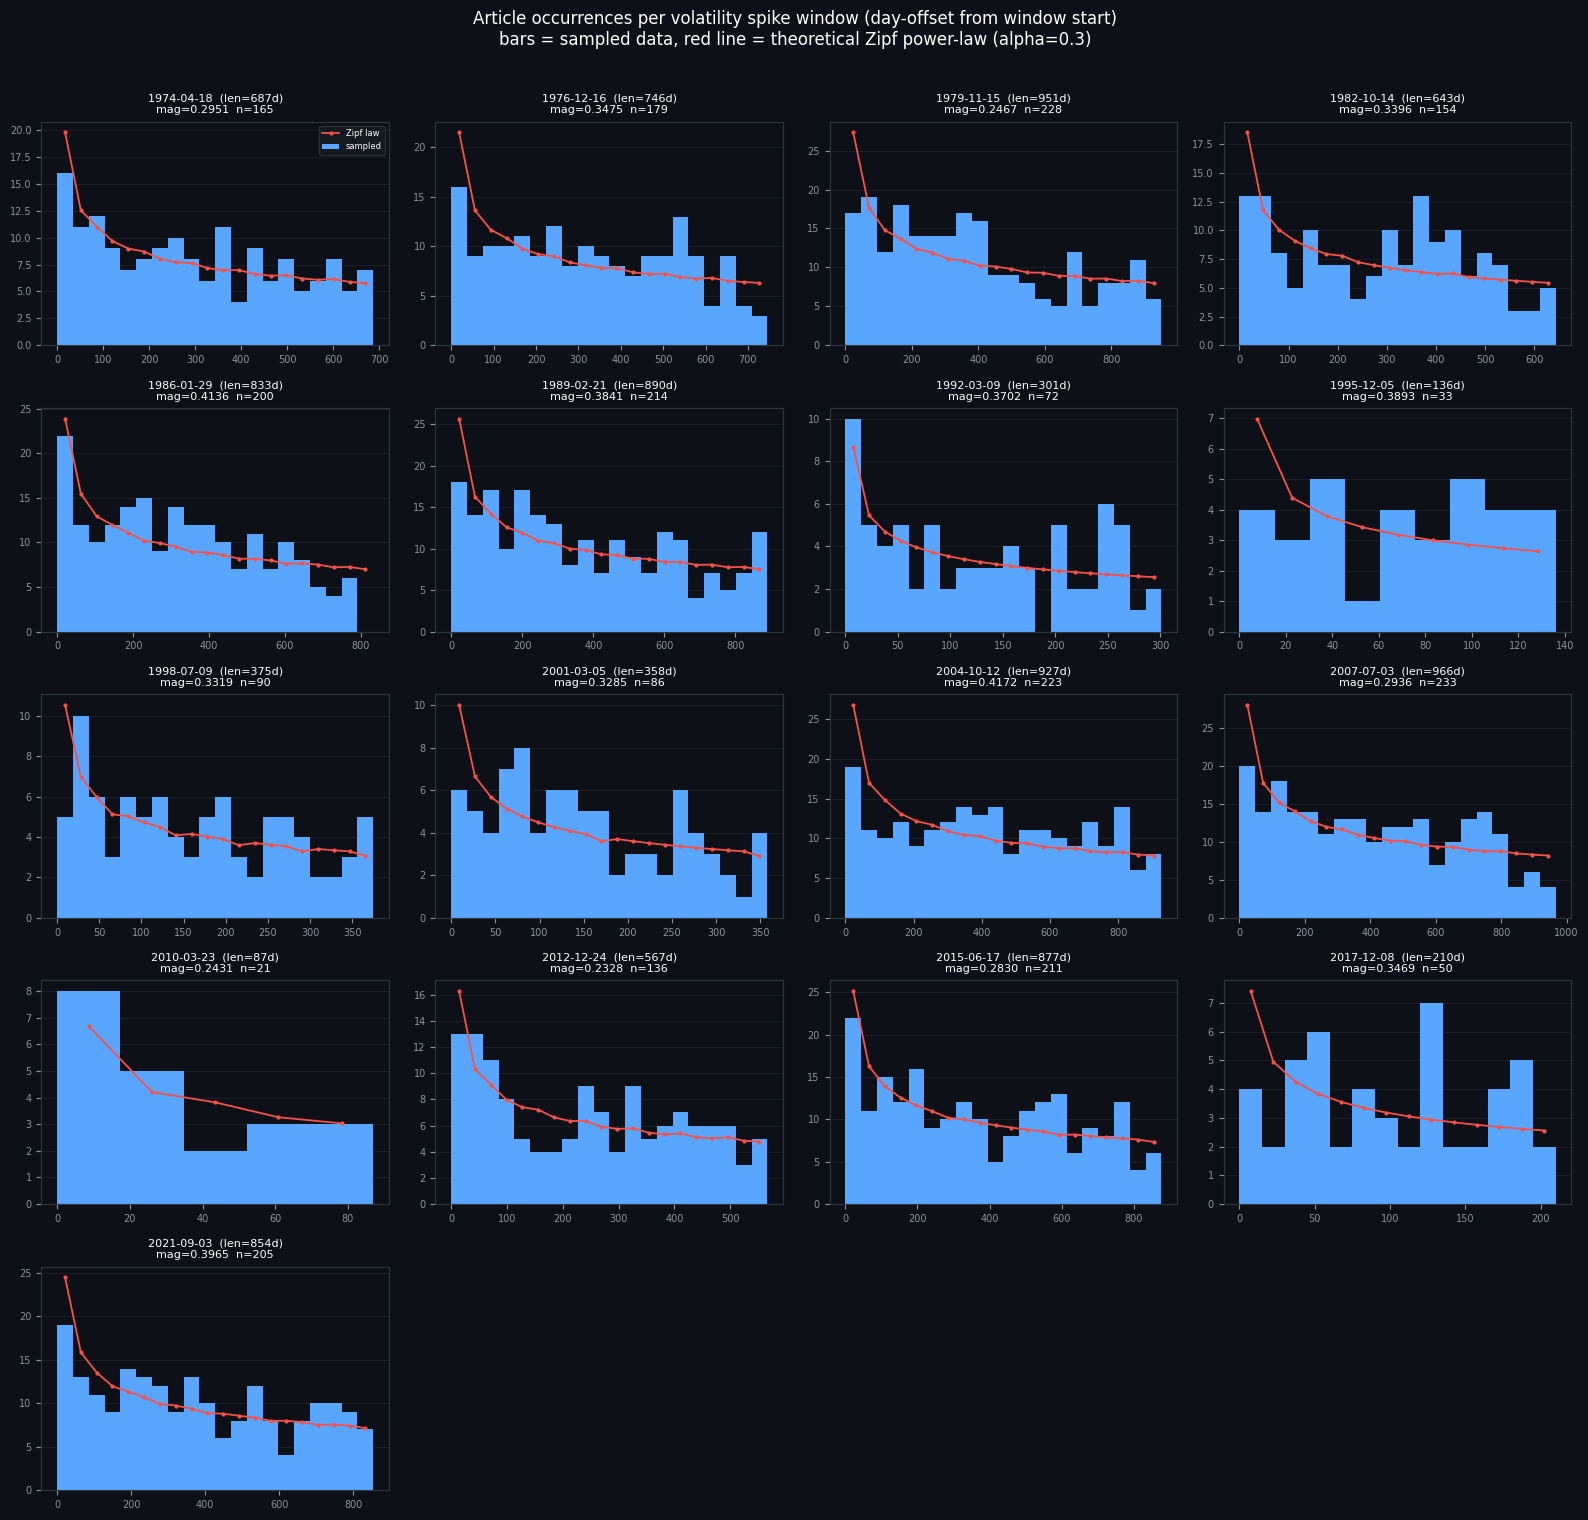

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Re-run simulate() in-memory instead of loading a baseline CSV ──
# (sample_var_dataset.py never saves an unsampled baseline file —
# only the final articles_...csv)
result_low = simulate(SEED, "low")
DATES_arr  = DATES

# ── Load the already-sampled final dataset ──────────────────────────
final = pd.read_csv("../data/stock_prices/articles_inflation_unemployment_var_low_seed7.csv",
                     parse_dates=["date"])

# ── Use inside_windows and window_spike_mags directly from simulate() ──
windows = [
    (DATES_arr[s], DATES_arr[min(e, len(DATES_arr) - 1)], mag)
    for (s, e), mag in zip(result_low["inside_windows"], result_low["window_spike_mags"])
]
print(f"Found {len(windows)} break windows")

# ── Build a grid of subplots, one per window ────────────────────────
n_windows = len(windows)
n_cols    = 4
n_rows    = int(np.ceil(n_windows / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows),
                          facecolor="#0d1117")
axes = axes.flatten()

for i, (start_date, end_date, mag) in enumerate(windows):
    ax      = axes[i]
    mask    = (final["date"] >= start_date) & (final["date"] < end_date)
    offsets = (final.loc[mask, "date"] - start_date).dt.days
    length  = (end_date - start_date).days
    n_here  = len(offsets)

    ax.set_facecolor("#0d1117")
    if n_here > 0:
        n_bins = max(5, min(20, length // 15))
        counts, edges = np.histogram(offsets, bins=n_bins, range=(0, length))
        ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
               color="#58a6ff", edgecolor="none", label="sampled")

        # ── theoretical Zipf law, scaled to this window's n_here ──
        theo_weights = zipf_window_weights(length, alpha=ZIPF_ALPHA)
        bin_idx      = np.digitize(np.arange(length), edges[1:-1])
        expected     = np.array([theo_weights[bin_idx == b].sum() * n_here
                                  for b in range(len(edges) - 1)])
        bin_centers  = (edges[:-1] + edges[1:]) / 2
        ax.plot(bin_centers, expected, color="#f85149", lw=1.3,
                marker="o", markersize=2, label="Zipf law")

    ax.set_title(f"{start_date.date()}  (len={length}d)\n"
                 f"mag={mag:.4f}  n={n_here}",
                 color="white", fontsize=8)
    ax.tick_params(colors="#8b949e", labelsize=7)
    for spine in ax.spines.values():
        spine.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d",
                  labelcolor="white", fontsize=6, loc="upper right")

# hide any unused subplot axes
for j in range(n_windows, len(axes)):
    axes[j].axis("off")

fig.suptitle("Article occurrences per volatility spike window (day-offset from window start)\n"
             "bars = sampled data, red line = theoretical Zipf power-law "
             f"(alpha={ZIPF_ALPHA})",
             color="white", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

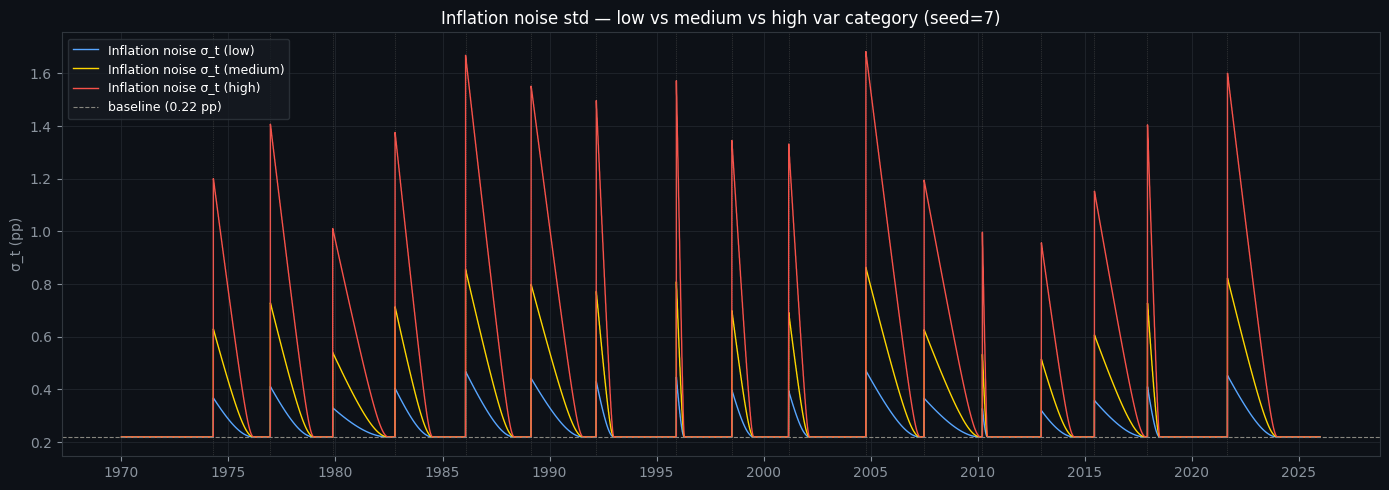

In [66]:
import matplotlib.dates as mdates
cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Additional plot: inflation volatility (sigma) across all three categories ──
fig2, ax = plt.subplots(figsize=(14, 5), facecolor="#0d1117")
ax.set_facecolor("#0d1117")
for cat in ("low", "medium", "high"):
    ax.plot(DATES, results[cat]["sigma_inflation_t"],
            color=cat_colors[cat], lw=1.0, label=f"Inflation noise σ_t ({cat})")
ax.axhline(SIGMA_INFLATION, color="#888780", ls="--", lw=0.8,
           label=f"baseline ({SIGMA_INFLATION:.2f} pp)")
for start_i, end_i in results["low"]["inside_windows"]:
    ax.axvline(DATES[start_i], color="#888780", ls=":", lw=0.5, alpha=0.5)
ax.set_title("Inflation noise std — low vs medium vs high var category (seed=7)",
                color="white", fontsize=12)
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.set_ylabel("σ_t (pp)", color="#8b949e")
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

### 4.4 Sampling Inflation and Unemployment Stock Prices for different magnitudes of correlation between unemployment and inflation

In [67]:
"""
Builds three balanced CSV datasets from the synthetic Inflation & Unemployment
CORRELATION (rho) simulation.

Each CSV contains 5000 rows:
  - 2500 outside a break window (evenly spaced dates)
  - 2500 inside a break window (each window's own sample count
    proportional to its LENGTH, dates within a window drawn from a
    truncated power-law/Zipf profile)

CORRELATION (rates in percent):
  Baseline = trend + white noise from "3. Test samples", the two noises are
  independent. INSIDE each window unemployment's noise is mixed with
  inflation's noise so that their correlation is rho_t = rho * frac_t
  (rho = 0.40 / 0.70 / 0.90 for low / medium / high, frac_t = 1 at the
  window start, linear decay to 0). Outside the windows both series are
  the baseline. Inflation is IDENTICAL across all three rho files; only
  unemployment's path changes.

COMMODITY TOPICS:
  Each row gets a "commodity_topics" column (comma-separated) listing
  1-2 commodities the article discusses, sampled in two stages:
    1. sample_n_topics: number of topics, a properly truncated Poisson
       (lambda=1.2) over [1,2]
    2. sample_commodities: WHICH commodities, drawn without replacement,
       weighted by a time-varying {inflation, unemployment} distribution
       -- inside a break window this is Zipf-shaped and inflation-dominant;
       outside any break window it is exactly uniform (50% each).
  The "inflation"/"unemployment" columns are MULTI-HOT indicators of
  commodity_topics (can have multiple 1s per row).

PRICE DATA:
  price_inflation/price_unemployment (and their log_price/dev counterparts) are
  populated ONLY when that commodity was actually sampled as a topic
  for that row.

Output files:
    ../data/stock_prices/articles_inflation_unemployment_rho_low_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_rho_medium_seed7.csv
    ../data/stock_prices/articles_inflation_unemployment_rho_high_seed7.csv
"""

import os
import numpy as np
import pandas as pd

# ── Fixed configuration ────────────────────────────────────────────
START = "1970-01-01"
END   = "2025-12-31"


RHO_CATEGORIES = {
    "low":    0.40,
    "medium": 0.70,
    "high":   0.90,
}

H_MIN, H_MAX = 60, 750

# (no break sizes here: rho only changes the noise correlation;
#  windows are placed exactly as in 4.1 / 4.3)
BUFFER_DAYS = 20   # minimum gap enforced between consecutive break windows
ZIPF_ALPHA  = 0.3  # power-law decay exponent (see zipf_window_weights)

SEED    = 7
OUT_DIR = "../data/stock_prices"

DATES = pd.bdate_range(START, END)
N     = len(DATES)
T     = np.arange(N) / 252.0

# ── Baseline = output of the simulation under "3. Test samples" ─────
# (smooth long-run trend + i.i.d. white noise, in percent). It is the
# single source of truth: every generator below only ADDS its effect
# inside the windows, so all "out" dates are identical to this baseline.
BASELINE_PATH = os.path.join(OUT_DIR, f"baseline_inflation_unemployment_trial_seed{SEED}.csv")
_base = pd.read_csv(BASELINE_PATH, parse_dates=["date"])
assert len(_base) == N and (_base["date"].to_numpy() == DATES.to_numpy()).all(), \
    "baseline file does not match DATES -- re-run the cell under '3. Test samples' first"
TREND_INFLATION    = _base["inflation_trend"].to_numpy()
TREND_UNEMPLOYMENT = _base["unemployment_trend"].to_numpy()
NOISE_INFLATION    = _base["inflation_price"].to_numpy()    - TREND_INFLATION
NOISE_UNEMPLOYMENT = _base["unemployment_price"].to_numpy() - TREND_UNEMPLOYMENT
SIGMA_INFLATION    = float(NOISE_INFLATION.std())      # ~0.22 pp
SIGMA_UNEMPLOYMENT = float(NOISE_UNEMPLOYMENT.std())   # ~0.10 pp


def safe_log(x) -> np.ndarray:
    """log of a rate; NaN where the rate is <= 0 (e.g. deflation)."""
    x = np.asarray(x, dtype=float)
    return np.log(np.where(x > 0, x, np.nan))


# ══════════════════════════════════════════════════════════════════
# Commodity topic selection
# ══════════════════════════════════════════════════════════════════
N_YEARS = 56  # 1970-2025 inclusive

INFLATION_ALPHA,   INFLATION_FLOOR,   INFLATION_SCALE   = 0.3, 2.5, 4.5
UNEMPLOYMENT_ALPHA, UNEMPLOYMENT_FLOOR, UNEMPLOYMENT_SCALE = 0.5, 1.2, 0.8

# ── Rho-dependent commodity input probabilities ─────────────────────
# Chosen directly (not derived from a formula) so that inflation and unemployment
# move CLOSER TOGETHER as rho_category strengthens. Under
# without-replacement sampling, balanced weights produce HIGHER joint
# co-occurrence than disparate weights, so this makes inflation+unemployment
# co-occurrence in article topics track the underlying price
# correlation strength -- verified empirically: P(both) rises
# monotonically ~0.29 (low) -> 0.31 (medium) -> 0.32 (high).
COMMODITY_INPUT_PROBS = {
    "low":    {"inflation": 0.6875, "unemployment": 0.3125},
    "medium": {"inflation": 0.5625, "unemployment": 0.4375},
    "high":   {"inflation": 0.5, "unemployment": 0.5},
}


def build_shape(alpha: float, n_years: int = N_YEARS) -> np.ndarray:
    """Truncated Zipf (power-law) decay shape, rescaled to [0, 1]."""
    raw = np.power(np.arange(1, n_years + 1), -alpha)
    return raw / raw.max()


inflation_shape   = build_shape(INFLATION_ALPHA)
unemployment_shape = build_shape(UNEMPLOYMENT_ALPHA)


def commodity_probs(t_years: float, inside: bool = True,
                    rho_category: str = None) -> dict:
    """
    Returns {"inflation", "unemployment"} -> probability.

    inside=True, rho_category given : uses COMMODITY_INPUT_PROBS[rho_category]
        -- inflation and unemployment's relative weights are chosen directly (not
        derived from a formula) so that as rho_category strengthens
        (low -> medium -> high), inflation and unemployment's probabilities move
        CLOSER TOGETHER. Under without-replacement sampling, balanced
        weights produce HIGHER joint co-occurrence than disparate
        weights (verified empirically: P(both) rises monotonically
        from ~0.29 at low to ~0.31 at medium to ~0.32 at high), so this
        directly reflects the underlying price correlation strength in
        the article topic co-occurrence rate.
    inside=False : uniform 50% each (used OUTSIDE any break window),
        independent of rho_category.
    """
    if not inside:
        probs = {"inflation": 0.5, "unemployment": 0.5}
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    if rho_category is not None:
        probs = dict(COMMODITY_INPUT_PROBS[rho_category])
        assert all(p >= 0 for p in probs.values())
        assert abs(sum(probs.values()) - 1.0) < 1e-9
        return probs

    # Fallback: original time-varying Zipf-shaped distribution, used
    # only if no rho_category is supplied.
    idx = int(np.clip(round(t_years), 0, N_YEARS - 1))
    g = INFLATION_FLOOR   + INFLATION_SCALE   * inflation_shape[idx]
    s = UNEMPLOYMENT_FLOOR + UNEMPLOYMENT_SCALE * unemployment_shape[idx]
    remaining = 1.0
    gs_total  = g + s
    probs = {
        "inflation":   remaining * (g / gs_total),
        "unemployment": remaining * (s / gs_total),
    }
    assert all(p >= 0 for p in probs.values()), "negative probability produced"
    assert abs(sum(probs.values()) - 1.0) < 1e-9, "probabilities do not sum to 1"
    return probs


def sample_commodity(rng: np.random.Generator, t_years: float,
                     inside: bool = True, rho_category: str = None) -> str:
    """Sample one commodity name (see commodity_probs)."""
    p = commodity_probs(t_years, inside=inside, rho_category=rho_category)
    return rng.choice(list(p.keys()), p=list(p.values()))


def sample_n_topics(rng: np.random.Generator, lam: float = 1.2,
                    low: int = 1, high: int = 2) -> int:
    """
    Number of distinct commodities discussed in one article.
    Properly truncated Poisson over [low, high], renormalized over the
    restricted support.
    """
    from scipy.stats import poisson
    k   = np.arange(low, high + 1)
    pmf = poisson.pmf(k, lam)
    pmf = pmf / pmf.sum()
    return int(rng.choice(k, p=pmf))


def sample_commodities(rng: np.random.Generator, t_years: float,
                       inside: bool = True, rho_category: str = None) -> list:
    """
    Sample a LIST of 1-4 distinct commodity names discussed in one
    article: first the COUNT (sample_n_topics, truncated Poisson),
    then WHICH commodities (weighted, without replacement, using the
    same inside/outside/rho-dependent distribution as sample_commodity).
    """
    n = sample_n_topics(rng)
    p = commodity_probs(t_years, inside=inside, rho_category=rho_category)
    names = list(p.keys())
    probs = np.array(list(p.values()))
    chosen = rng.choice(names, size=n, replace=False, p=probs)
    return sorted(chosen.tolist())
# ══════════════════════════════════════════════════════════════════

# ── Simulation ─────────────────────────────────────────────────────

def simulate(seed: int, rho_category: str) -> dict:
    """
    Baseline (trend + white noise) where, INSIDE the windows, the noise
    of unemployment becomes correlated with the noise of inflation:

        z_unemp,t' = rho_t * z_infl,t + sqrt(1 - rho_t^2) * z_unemp,t
        rho_t      = RHO_CATEGORIES[rho_category] * frac_t

    (frac_t = 1 at the window start, linear decay to 0). Outside the
    windows rho_t = 0, so both series are bit-for-bit the baseline;
    inflation is the baseline everywhere, only unemployment changes.
    """
    rho = RHO_CATEGORIES[rho_category]
    rng = np.random.default_rng(seed)

    n_struc = int(rng.integers(11, 18))
    h_js    = rng.integers(H_MIN, H_MAX + 1, size=n_struc)

    margin  = H_MAX
    spacing = (N - 2 * margin) / n_struc
    t_struc = []
    for j in range(n_struc):
        center = margin + (j + 0.5) * spacing
        jitter = rng.uniform(-spacing * 0.3, spacing * 0.3)
        t_struc.append(int(np.clip(center + jitter, margin, N - margin)))

    order   = np.argsort(t_struc)
    t_struc = np.array(t_struc)[order]
    h_js    = h_js[order]

    # Enforce minimum gap + buffer between windows so each effect
    # genuinely decays to zero before the next window starts.
    for j in range(1, n_struc):
        min_gap = max(h_js[j - 1], h_js[j]) + BUFFER_DAYS
        if t_struc[j] - t_struc[j - 1] < min_gap:
            t_struc[j] = t_struc[j - 1] + min_gap

    dev_inflation    = np.zeros(N)
    dev_unemployment = np.zeros(N)
    inside_mask      = np.zeros(N, dtype=bool)
    rho_t            = np.zeros(N)
    for bp, h_j in zip(t_struc, h_js):
        end_i = min(bp + h_j, N)
        inside_mask[bp:end_i] = True
        rho_t[bp:end_i] = rho * (1 - (np.arange(bp, end_i) - bp) / h_j)

    z_inflation    = NOISE_INFLATION    / SIGMA_INFLATION
    z_unemployment = NOISE_UNEMPLOYMENT / SIGMA_UNEMPLOYMENT
    z_unemployment_corr = rho_t * z_inflation + np.sqrt(1 - rho_t ** 2) * z_unemployment

    price_inflation    = TREND_INFLATION    + NOISE_INFLATION
    price_unemployment = TREND_UNEMPLOYMENT + SIGMA_UNEMPLOYMENT * z_unemployment_corr

    return {
        "rho":                rho,
        "rho_t":              rho_t,
        "inside_mask":        inside_mask,
        "inside_windows":     list(zip(t_struc.tolist(), (np.minimum(t_struc + h_js, N)).tolist())),
        "window_break_mags":  [rho] * n_struc,                  # correlation at window start
        "dev_inflation":      dev_inflation,
        "dev_unemployment":   dev_unemployment,
        "logp_inflation":     safe_log(price_inflation),
        "logp_unemployment":  safe_log(price_unemployment),
        "price_inflation":    price_inflation,
        "price_unemployment": price_unemployment,
    }


def even_sample(idx_array: np.ndarray, n: int) -> np.ndarray:
    """Pick n indices evenly spaced across idx_array (by position)."""
    positions = np.round(np.linspace(0, len(idx_array) - 1, n)).astype(int)
    return idx_array[positions]


def zipf_window_weights(length: int, alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Truncated discrete power-law (Zipf) weights for positions 1..length.

    alpha = 0.3 is chosen based on:
      Zawadowski, A., Kertesz, J., & Andor, G. (2004). "Short-term
      market reaction after extreme price changes of liquid stocks."
      https://arxiv.org/abs/cond-mat/0406696

    The truncated (finite-support) Zipf distribution used here follows:
      Boamah-Addo, K., Kozubowski, T. J., & Panorska, A. K. (2023).
      "A discrete truncated Zipf distribution." Statistica Neerlandica,
      77(2), 156-187. https://doi.org/10.1111/stan.12280
    """
    day = np.arange(1, length + 1, dtype=float)
    w   = np.power(day, -alpha)
    return w / w.sum()


def sample_inside_dates(result: dict, n_total: int, rng: np.random.Generator,
                        alpha: float = ZIPF_ALPHA) -> np.ndarray:
    """
    Sample n_total inside indices total, with each window's OWN sample
    count determined INDEPENDENTLY, proportional to that window's
    LENGTH -- no magnitude weighting, no global pooled draw.
    """
    windows    = result["inside_windows"]
    lengths    = np.array([e - s for s, e in windows])
    total_days = lengths.sum()

    quotas = np.round(n_total * lengths / total_days).astype(int)
    quotas = np.clip(quotas, 0, lengths)

    diff = n_total - quotas.sum()
    if diff != 0:
        order = np.argsort(-lengths)
        for idx in order:
            if diff == 0:
                break
            if diff > 0 and quotas[idx] < lengths[idx]:
                quotas[idx] += 1
                diff -= 1
            elif diff < 0 and quotas[idx] > 0:
                quotas[idx] -= 1
                diff += 1

    all_samples = []
    for (start_i, end_i), quota in zip(windows, quotas):
        if quota <= 0:
            continue
        window_idx = np.arange(start_i, end_i)
        weights    = zipf_window_weights(len(window_idx), alpha=alpha)
        samples    = rng.choice(window_idx, size=int(quota), replace=False, p=weights)
        all_samples.append(samples)

    return np.concatenate(all_samples) if all_samples else np.array([], dtype=int)


# ── Simulate all three rho categories ──────────────────────────────
print("Simulating all three rho categories...")
results = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

# Sanity check: inflation price + break structure identical across all rho levels
assert np.allclose(results["low"]["price_inflation"], results["medium"]["price_inflation"]), \
    "Inflation rates differ between low and medium!"
assert np.allclose(results["low"]["price_inflation"], results["high"]["price_inflation"]), \
    "Inflation rates differ between low and high!"
assert np.array_equal(results["low"]["inside_mask"], results["medium"]["inside_mask"]), \
    "Inside masks differ between low and medium!"
assert np.array_equal(results["low"]["inside_mask"], results["high"]["inside_mask"]), \
    "Inside masks differ between low and high!"
print("Sanity check passed: inflation price and break structure identical across all rho levels.\n")

outside_idx = np.where(~results["low"]["inside_mask"])[0]
print(f"Break structure: {len(outside_idx)} outside days, "
      f"{results['low']['inside_mask'].sum()} inside days (out of {N} total)")

# ── Sample indices ─────────────────────────────────────────────────
outside_sample_idx = even_sample(outside_idx, 2500)

inside_rng = np.random.default_rng(SEED + 1)
inside_sample_idx = sample_inside_dates(results["low"], 2500, inside_rng)

sample_idx = np.concatenate([outside_sample_idx, inside_sample_idx])
print(f"Sampled {len(outside_sample_idx)} outside + {len(inside_sample_idx)} inside "
      f"= {len(sample_idx)} total dates")

os.makedirs(OUT_DIR, exist_ok=True)

# ── Commodity topic label sampling ──────────────────────────────────
# NOW INTENTIONALLY DIFFERS across rho categories: inflation and unemployment's
# input probabilities depend on rho_category (see COMMODITY_INPUT_PROBS),
# converging toward each other as rho strengthens, which drives HIGHER
# inflation+unemployment co-occurrence in article topics at higher correlation
# levels.
commodity_topic_seed_base = SEED + 4

# ── Build and save one CSV per rho category ────────────────────────
for cat in ("low", "medium", "high"):
    result = results[cat]
    rows   = []
    commodity_topic_rng = np.random.default_rng(commodity_topic_seed_base)

    for obs_id, idx in enumerate(sample_idx):
        topics     = sample_commodities(commodity_topic_rng, T[idx],
                                        inside=bool(result["inside_mask"][idx]),
                                        rho_category=cat)
        has_inflation   = "inflation"   in topics
        has_unemployment = "unemployment" in topics
        rows.append({
            "obs_id":           obs_id,
            "date":             DATES[idx],
            "t_years":          T[idx],
            "inflation":             int(has_inflation),
            "unemployment":           int(has_unemployment),
            "commodity_topics": ",".join(topics),
            "price_inflation":       result["price_inflation"][idx]   if has_inflation   else None,
            "log_price_inflation":   result["logp_inflation"][idx]    if has_inflation   else None,
            "dev_inflation":         result["dev_inflation"][idx]     if has_inflation   else None,
            "price_unemployment":     result["price_unemployment"][idx] if has_unemployment else None,
            "log_price_unemployment": result["logp_unemployment"][idx]  if has_unemployment else None,
            "dev_unemployment":       result["dev_unemployment"][idx]   if has_unemployment else None,
            "label":            int(result["inside_mask"][idx]),
            "IN":               int(result["inside_mask"][idx]),
        })

    df_out = (
        pd.DataFrame(rows)
        .sort_values("obs_id")
        .reset_index(drop=True)
    )

    csv_path = os.path.join(
        OUT_DIR, f"articles_inflation_unemployment_rho_{cat}_seed{SEED}.csv")
    df_out.to_csv(csv_path, index=False)

    n_inside     = (df_out["label"] == 1).sum()
    n_outside    = (df_out["label"] == 0).sum()
    topic_counts = df_out["commodity_topics"].value_counts().to_dict()
    print(f"[{cat:6s}]  {len(df_out)} rows  (rho={RHO_CATEGORIES[cat]})  "
          f"inside={n_inside}, outside={n_outside}  →  {csv_path}")
    print(f"          commodity_topic distribution: {topic_counts}")

print("\nDone.")

Simulating all three rho categories...
Sanity check passed: inflation price and break structure identical across all rho levels.

Break structure: 7174 outside days, 7436 inside days (out of 14610 total)
Sampled 2500 outside + 2500 inside = 5000 total dates
[low   ]  5000 rows  (rho=0.4)  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_rho_low_seed7.csv
          commodity_topic distribution: {'inflation': 1930, 'inflation,unemployment': 1888, 'unemployment': 1182}
[medium]  5000 rows  (rho=0.7)  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_rho_medium_seed7.csv
          commodity_topic distribution: {'inflation,unemployment': 1908, 'inflation': 1737, 'unemployment': 1355}
[high  ]  5000 rows  (rho=0.9)  inside=2500, outside=2500  →  ../data/stock_prices/articles_inflation_unemployment_rho_high_seed7.csv
          commodity_topic distribution: {'inflation,unemployment': 1872, 'inflation': 1644, 'unemployment': 148

In [68]:
# ── Save the FULL continuous series (every business day, not just
# the 5000-row sample) for each category, into data/stock_prices/full_series/.
# Needed for genuine 21-day price lookback -- the sparse sampled files
# null out price_inflation/price_unemployment on any row where that commodity
# isn't a topic, which makes row-based lookback mostly empty.
FULL_SERIES_DIR = "../data/stock_prices/full_series"
os.makedirs(FULL_SERIES_DIR, exist_ok=True)

for cat in ("low", "medium", "high"):
    result = results[cat]
    full_df = pd.DataFrame({
        "date":             DATES,
        "t_years":          T,
        "inflation_price":       result["price_inflation"],
        "unemployment_price":     result["price_unemployment"],
        "inflation_log_price":   result["logp_inflation"],
        "unemployment_log_price": result["logp_unemployment"],
        "inflation_dev":         result["dev_inflation"],
        "unemployment_dev":       result["dev_unemployment"],
        "is_break":         result["inside_mask"].astype(int),
    })
    full_path = os.path.join(
        FULL_SERIES_DIR, f"full_articles_inflation_unemployment_rho_{cat}_seed{SEED}.csv")
    full_df.to_csv(full_path, index=False)
    print(f"[{cat:6s}]  full continuous series ({len(full_df)} rows) -> {full_path}")



[low   ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_rho_low_seed7.csv
[medium]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_rho_medium_seed7.csv
[high  ]  full continuous series (14610 rows) -> ../data/stock_prices/full_series/full_articles_inflation_unemployment_rho_high_seed7.csv


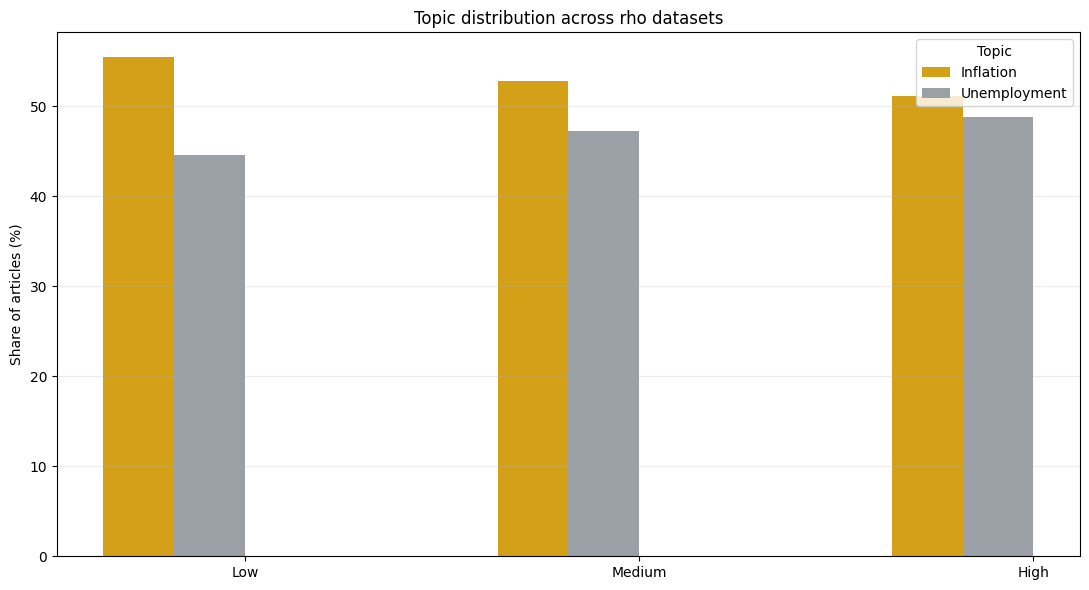

In [69]:
"""Plot topic distributions for the three rho datasets.

The script reads the three CSVs generated by the data notebook and plots the
prevalence of each commodity topic across the datasets.

Usage:
    python notes/examples/plot_topic_distributions.py
    python notes/examples/plot_topic_distributions.py --output cache/topic_distribution.png
"""

from __future__ import annotations

import argparse
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


DEFAULT_DATASETS = {
    "low": Path("../data/stock_prices/articles_inflation_unemployment_rho_low_seed7.csv"),
    "medium": Path("../data/stock_prices/articles_inflation_unemployment_rho_medium_seed7.csv"),
    "high": Path("../data/stock_prices/articles_inflation_unemployment_rho_high_seed7.csv"),
}

TOPIC_ORDER = ["inflation", "unemployment"]
TOPIC_COLORS = {
    "inflation": "#d4a017",
    "unemployment": "#9aa0a6",
}


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Plot topic distributions for the rho datasets.")
    parser.add_argument(
        "--output",
        type=Path,
        default=Path("cache/topic_distribution.png"),
        help="Optional path to save the figure instead of only showing it.",
    )
    parser.add_argument(
        "--absolute",
        action="store_true",
        help="Plot absolute counts instead of percentages of articles.",
    )
    args, _ = parser.parse_known_args()
    return args


def load_dataset(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"Missing dataset: {path}")
    return pd.read_csv(path)


def topic_counts(df: pd.DataFrame) -> pd.Series:
    topics = (
        df["commodity_topics"]
        .fillna("")
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )
    topics = topics[topics != ""]
    counts = topics.value_counts()
    return counts.reindex(TOPIC_ORDER, fill_value=0)


def build_plot(data: dict[str, pd.Series], absolute: bool) -> tuple[plt.Figure, plt.Axes]:
    labels = list(data.keys())
    x_positions = range(len(labels))
    width = 0.18

    fig, ax = plt.subplots(figsize=(11, 6))
    for offset, topic in enumerate(TOPIC_ORDER):
        values = []
        for label in labels:
            series = data[label]
            value = float(series[topic])
            if not absolute:
                value = value / series.sum() * 100.0
            values.append(value)

        ax.bar(
            [x + (offset - 1.5) * width for x in x_positions],
            values,
            width=width,
            label=topic.capitalize(),
            color=TOPIC_COLORS[topic],
        )

    ax.set_xticks(list(x_positions))
    ax.set_xticklabels([label.capitalize() for label in labels])
    ax.set_ylabel("Count" if absolute else "Share of articles (%)")
    ax.set_title("Topic distribution across rho datasets")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(title="Topic")
    fig.tight_layout()
    return fig, ax


def main() -> None:
    args = parse_args()

    counts_by_dataset: dict[str, pd.Series] = {}
    for label, path in DEFAULT_DATASETS.items():
        df = load_dataset(path)
        counts_by_dataset[label] = topic_counts(df)

    fig, _ = build_plot(counts_by_dataset, absolute=args.absolute)

    # if args.output:
    #     args.output.parent.mkdir(parents=True, exist_ok=True)
    #     fig.savefig(args.output, dpi=180, bbox_inches="tight")
    #     print(f"Saved figure to {args.output}")

    plt.show()


if __name__ == "__main__":
    main()

# 5. Sanity Check of the sampled datasets

## 5.1 Verify Commodity Proportions

In [70]:
VAR_CATEGORIES = {   # extra noise std = k * base sigma (see 4.3)
    "low":    (1.0, 2.0),
    "medium": (2.0, 4.0),
    "high":   (4.0, 8.0),
}

## 5.2 Counts

In [71]:
from pathlib import Path
import pandas as pd

base_dir = Path("../data/stock_prices")
dataset_specs = [
    {"name": "struct_low",    "path": base_dir / "articles_inflation_unemployment_struct_low_seed7.csv"},
    {"name": "struct_medium", "path": base_dir / "articles_inflation_unemployment_struct_medium_seed7.csv"},
    {"name": "struct_high",   "path": base_dir / "articles_inflation_unemployment_struct_high_seed7.csv"},
    {"name": "var_low",       "path": base_dir / "articles_inflation_unemployment_var_low_seed7.csv"},
    {"name": "var_medium",    "path": base_dir / "articles_inflation_unemployment_var_medium_seed7.csv"},
    {"name": "var_high",      "path": base_dir / "articles_inflation_unemployment_var_high_seed7.csv"},
    {"name": "rho_low",       "path": base_dir / "articles_inflation_unemployment_rho_low_seed7.csv"},
    {"name": "rho_medium",    "path": base_dir / "articles_inflation_unemployment_rho_medium_seed7.csv"},
    {"name": "rho_high",      "path": base_dir / "articles_inflation_unemployment_rho_high_seed7.csv"},
]

summary_rows = [{"dataset": s["name"], "rows": len(pd.read_csv(s["path"]))} for s in dataset_specs]
summary = pd.DataFrame(summary_rows)

# Row counts for every dataset
row_counts = summary[["dataset", "rows"]].sort_values("dataset").reset_index(drop=True)
display(row_counts)
print("Total rows across all datasets:", int(row_counts["rows"].sum()))

,dataset,rows
0,rho_high,5000
1,rho_low,5000
2,rho_medium,5000
3,struct_high,5000
4,struct_low,5000
5,struct_medium,5000
6,var_high,5000
7,var_low,5000
8,var_medium,5000


Total rows across all datasets: 45000


## 5.3 Check Inflation and Unemployment Proportions

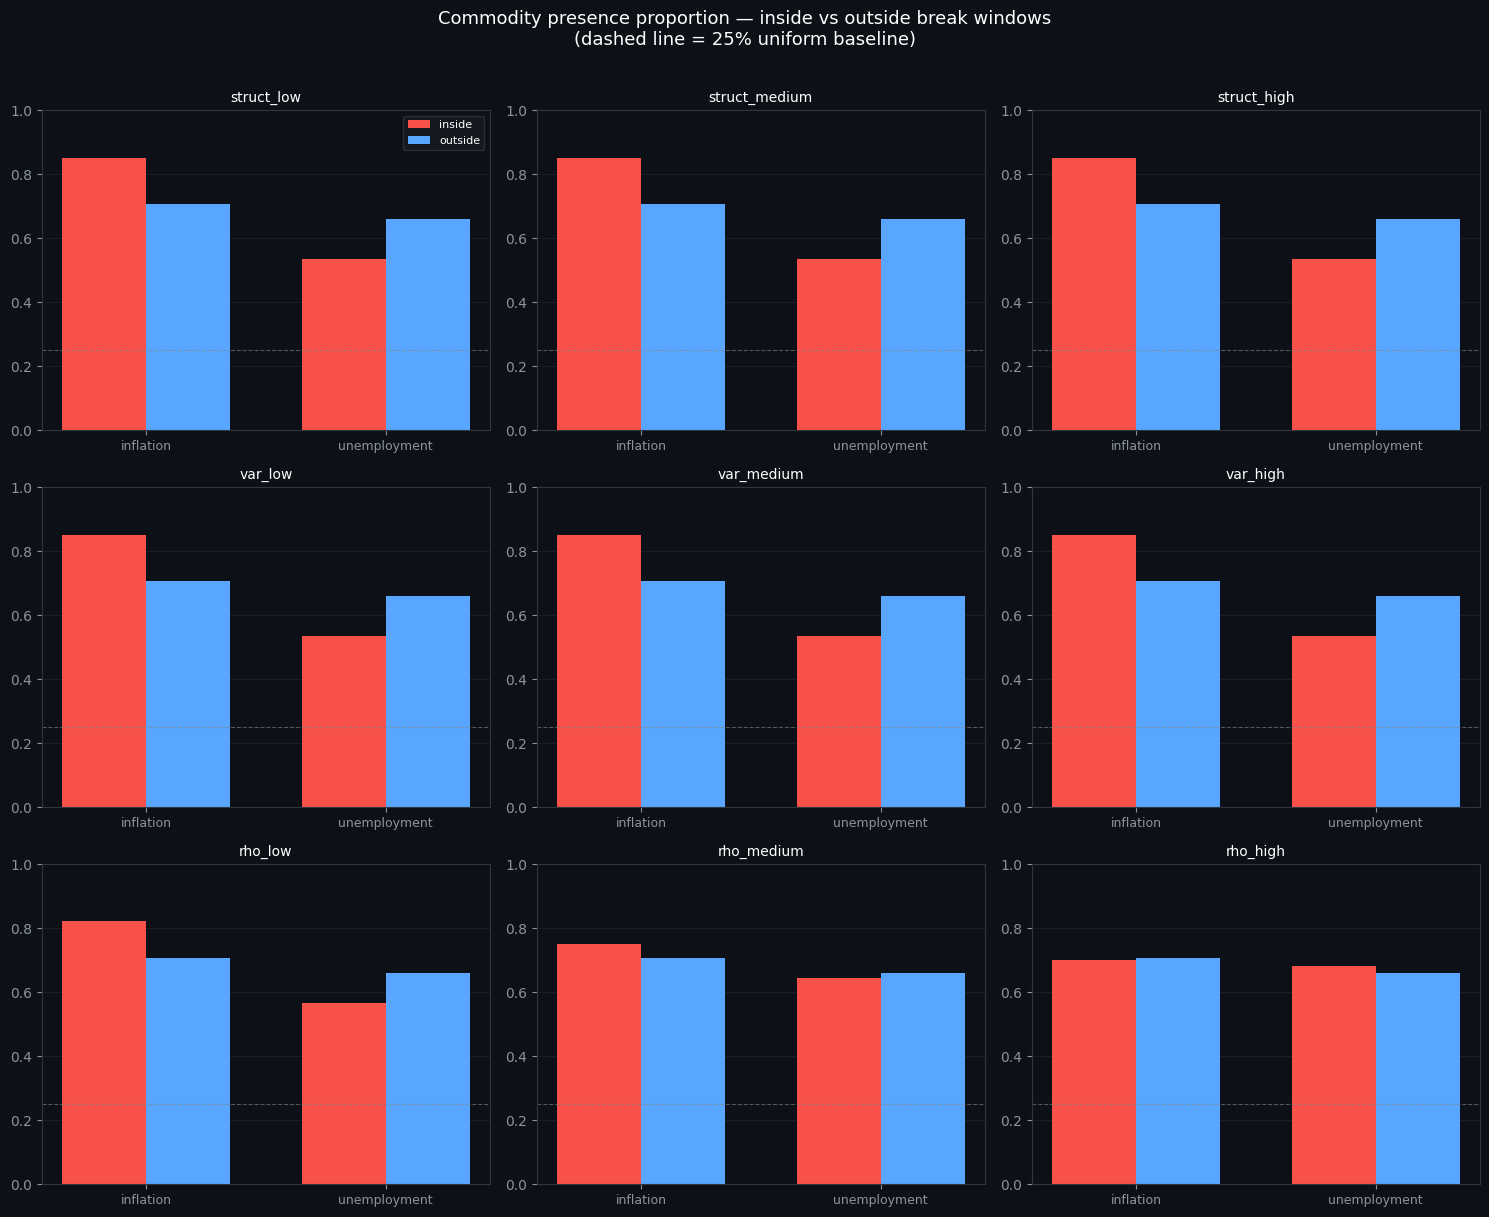

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base_dir = Path("../data/stock_prices")
COMMODITIES = ["inflation", "unemployment"]

# All 9 generated datasets: 3 categories (struct/var/rho) x 3 magnitude
# levels (low/medium/high). Each has "label" (1=inside break window,
# 0=outside) and one 0/1 column per commodity indicating whether that
# commodity was sampled as a topic for that row.
dataset_specs = [
    {"name": "struct_low",    "path": base_dir / "articles_inflation_unemployment_struct_low_seed7.csv"},
    {"name": "struct_medium", "path": base_dir / "articles_inflation_unemployment_struct_medium_seed7.csv"},
    {"name": "struct_high",   "path": base_dir / "articles_inflation_unemployment_struct_high_seed7.csv"},
    {"name": "var_low",       "path": base_dir / "articles_inflation_unemployment_var_low_seed7.csv"},
    {"name": "var_medium",    "path": base_dir / "articles_inflation_unemployment_var_medium_seed7.csv"},
    {"name": "var_high",      "path": base_dir / "articles_inflation_unemployment_var_high_seed7.csv"},
    {"name": "rho_low",       "path": base_dir / "articles_inflation_unemployment_rho_low_seed7.csv"},
    {"name": "rho_medium",    "path": base_dir / "articles_inflation_unemployment_rho_medium_seed7.csv"},
    {"name": "rho_high",      "path": base_dir / "articles_inflation_unemployment_rho_high_seed7.csv"},
]

# ── Aggregate commodity presence proportions, split by inside/outside ──
# For each dataset and each commodity, compute:
#   inside_props[c][i]  = P(commodity c present | row is inside a break window)
#   outside_props[c][i] = P(commodity c present | row is outside any break window)
# This directly visualizes the sampling design: INSIDE should be
# inflation-dominant and skewed (Zipf-shaped weights), OUTSIDE should be
# close to uniform 25% for every commodity.
inside_props  = {c: [] for c in COMMODITIES}
outside_props = {c: [] for c in COMMODITIES}
names = []

for spec in dataset_specs:
    df = pd.read_csv(spec["path"])
    inside  = df[df["label"] == 1]   # rows sampled from inside a break window
    outside = df[df["label"] == 0]   # rows sampled from outside any break window
    names.append(spec["name"])
    for c in COMMODITIES:
        # mean of a 0/1 column = fraction of rows where that commodity is present
        inside_props[c].append(inside[c].mean())
        outside_props[c].append(outside[c].mean())

# ── Plot: one grouped-bar subplot per dataset, arranged in a grid ──────
n_cols = 3
n_rows = int(np.ceil(len(names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows), facecolor="#0d1117")
axes = axes.flatten()

x = np.arange(len(COMMODITIES))
width = 0.35
colors = {"inside": "#f85149", "outside": "#58a6ff"}  # red=inside, blue=outside

for i, name in enumerate(names):
    ax = axes[i]
    ax.set_facecolor("#0d1117")
    inside_vals  = [inside_props[c][i]  for c in COMMODITIES]
    outside_vals = [outside_props[c][i] for c in COMMODITIES]

    # side-by-side bars: inside slightly left, outside slightly right
    ax.bar(x - width/2, inside_vals,  width, label="inside",  color=colors["inside"])
    ax.bar(x + width/2, outside_vals, width, label="outside", color=colors["outside"])

    # reference line at the theoretical uniform 25% baseline (what
    # "outside" should closely match, by design of commodity_probs)
    ax.axhline(0.25, color="#888780", ls="--", lw=0.8, alpha=0.6)

    ax.set_xticks(x)
    ax.set_xticklabels(COMMODITIES, color="#8b949e", fontsize=9)
    ax.set_ylim(0, 1)
    ax.set_title(name, color="white", fontsize=10)
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(axis="y", color="#21262d", linewidth=0.5)
    ax.set_axisbelow(True)
    if i == 0:
        ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=8)

# hide any unused grid cells (if len(names) doesn't fill the grid exactly)
for j in range(len(names), len(axes)):
    axes[j].axis("off")

fig.suptitle("Commodity presence proportion — inside vs outside break windows\n"
             "(dashed line = 25% uniform baseline)",
             color="white", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 5.4 Check dates

In [73]:
"""
Checks whether the SAME DATES were used across all generated datasets
(articles_inflation_unemployment_{struct|var|rho}_{low|medium|high}_seed7.csv),
and — where dates are shared — whether their IN/OUT (label) status
also matches.

Because all three simulation scripts (struct/var/rho) consume their
RNG in the same order up through the point where break positions
(t_struc, h_js) are drawn, and all three use the identical seed=7 and
the identical inside-sampling RNG (seed+1), the break window structure
and the actual sampled dates are EXPECTED to be identical across all
9 files. This script verifies that expectation empirically rather
than assuming it.

Checks performed:
  1. Within each family (struct, var, rho): are the 5000 dates
     identical across low/medium/high?
  2. Across families (struct vs var vs rho): are the 5000 dates
     identical?
  3. For any dates that ARE shared between two files, does the
     IN/OUT (label) status match?

Run from the notebooks/ directory:
    python check_date_consistency.py
"""

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("../data/stock_prices")

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"  [{status}]  {message}")
    if not condition:
        all_ok = False


# ── Load all current dataset files ──────────────────────────────────
files = sorted(DATA_DIR.glob("articles_inflation_unemployment_*_seed7.csv"))
print(f"Found {len(files)} dataset files:\n")
for f in files:
    print(f"  {f.name}")

datasets = {}
for f in files:
    df = pd.read_csv(f, parse_dates=["date"])
    # Use "IN" column if present, otherwise fall back to "label"
    label_col = "IN" if "IN" in df.columns else "label"
    df = df[["obs_id", "date", label_col]].rename(columns={label_col: "in_out"})
    datasets[f.stem] = df

# ── Group filenames by family (struct/var/rho) ──────────────────────
def family_of(name: str) -> str:
    for fam in ("struct", "var", "rho"):
        if f"_{fam}_" in name:
            return fam
    return "unknown"

families = {}
for name in datasets:
    families.setdefault(family_of(name), []).append(name)

# ══════════════════════════════════════════════════════════════════
# 1: Within-family date consistency (low vs medium vs high)
# ══════════════════════════════════════════════════════════════════
print("\n── Within-family date consistency (low vs medium vs high) ──────")
for fam, names in families.items():
    names = sorted(names)
    if len(names) < 2:
        continue
    print(f"\n{fam}:")
    ref_name = names[0]
    ref_dates = set(datasets[ref_name]["date"].astype(str))
    ref_in_out = datasets[ref_name].set_index("date")["in_out"]

    for name in names[1:]:
        other_dates = set(datasets[name]["date"].astype(str))
        dates_match = ref_dates == other_dates
        check(dates_match, f"same 5000 dates: {ref_name} vs {name}")

        if dates_match:
            other_in_out = datasets[name].set_index("date")["in_out"]
            # align by date and compare in/out status
            aligned = ref_in_out.to_frame("ref").join(
                other_in_out.to_frame("other"), how="inner")
            in_out_match = (aligned["ref"] == aligned["other"]).all()
            check(in_out_match,
                  f"IN/OUT status matches on all shared dates: "
                  f"{ref_name} vs {name}")
        else:
            shared = ref_dates & other_dates
            print(f"    (dates overlap: {len(shared)} / {len(ref_dates)} shared)")

# ══════════════════════════════════════════════════════════════════
# 2: Across-family date consistency (struct vs var vs rho)
# ══════════════════════════════════════════════════════════════════
print("\n── Across-family date consistency (struct vs var vs rho) ────────")
fam_names = sorted(families.keys())
# Use the "low" file from each family as the representative
representatives = {}
for fam in fam_names:
    low_candidates = [n for n in families[fam] if "_low_" in n]
    if low_candidates:
        representatives[fam] = low_candidates[0]

for i, fam_a in enumerate(fam_names):
    for fam_b in fam_names[i + 1:]:
        name_a = representatives.get(fam_a)
        name_b = representatives.get(fam_b)
        if name_a is None or name_b is None:
            continue

        dates_a = set(datasets[name_a]["date"].astype(str))
        dates_b = set(datasets[name_b]["date"].astype(str))
        dates_match = dates_a == dates_b
        check(dates_match, f"same 5000 dates: {name_a} ({fam_a}) vs {name_b} ({fam_b})")

        if dates_match:
            in_out_a = datasets[name_a].set_index("date")["in_out"]
            in_out_b = datasets[name_b].set_index("date")["in_out"]
            aligned = in_out_a.to_frame("a").join(in_out_b.to_frame("b"), how="inner")
            in_out_match = (aligned["a"] == aligned["b"]).all()
            check(in_out_match,
                  f"IN/OUT status matches on all shared dates: "
                  f"{name_a} ({fam_a}) vs {name_b} ({fam_b})")
        else:
            shared = dates_a & dates_b
            print(f"    (dates overlap: {len(shared)} / {len(dates_a)} shared)")
            if shared:
                in_out_a = datasets[name_a].set_index("date")["in_out"]
                in_out_b = datasets[name_b].set_index("date")["in_out"]
                aligned = in_out_a.to_frame("a").join(in_out_b.to_frame("b"), how="inner")
                mismatches = (aligned["a"] != aligned["b"]).sum()
                check(mismatches == 0,
                      f"IN/OUT status matches on the {len(shared)} shared dates "
                      f"({name_a} vs {name_b}), {mismatches} mismatches")

print(f"\n{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

Found 9 dataset files:

  articles_inflation_unemployment_rho_high_seed7.csv
  articles_inflation_unemployment_rho_low_seed7.csv
  articles_inflation_unemployment_rho_medium_seed7.csv
  articles_inflation_unemployment_struct_high_seed7.csv
  articles_inflation_unemployment_struct_low_seed7.csv
  articles_inflation_unemployment_struct_medium_seed7.csv
  articles_inflation_unemployment_var_high_seed7.csv
  articles_inflation_unemployment_var_low_seed7.csv
  articles_inflation_unemployment_var_medium_seed7.csv

── Within-family date consistency (low vs medium vs high) ──────

rho:
  [OK]  same 5000 dates: articles_inflation_unemployment_rho_high_seed7 vs articles_inflation_unemployment_rho_low_seed7
  [OK]  IN/OUT status matches on all shared dates: articles_inflation_unemployment_rho_high_seed7 vs articles_inflation_unemployment_rho_low_seed7
  [OK]  same 5000 dates: articles_inflation_unemployment_rho_high_seed7 vs articles_inflation_unemployment_rho_medium_seed7
  [OK]  IN/OUT status m

## 5.5 Check distribution of Dates

In [74]:
"""
Full pairwise (low vs medium, low vs high, medium vs high) check of
commodity_topics consistency WITHIN the struct family and WITHIN the
var family.

Expected result: 100% match on every pair, in both families -- struct
and var both use the same (non-rho-dependent) time-varying Zipf
commodity_probs formula, with commodity_topic_rng re-seeded identically
at the start of each category's loop, so the sampled article topics
are completely independent of the price magnitude/volatility category.
Only the underlying price VALUES should differ between low/medium/high;
the commodity_topics dimension should not.

(rho is intentionally excluded here -- since COMMODITY_INPUT_PROBS
makes inflation/unemployment's topic weights depend on rho_category, its
commodity_topics is EXPECTED to differ across low/medium/high; see
check_commodity_date_consistency.py for that comparison.)

Run from the notebooks/ directory:
    python check_struct_var_topic_consistency.py
"""

from pathlib import Path
from itertools import combinations
import pandas as pd

DATA_DIR    = Path("../data/stock_prices")
COMMODITIES = ["inflation", "unemployment"]

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"    [{status}]  {message}")
    if not condition:
        all_ok = False


def compare_topics(name_a: str, name_b: str, datasets: dict) -> None:
    df_a = datasets[name_a].set_index("date")
    df_b = datasets[name_b].set_index("date")

    aligned = df_a[["commodity_topics"] + COMMODITIES].join(
        df_b[["commodity_topics"] + COMMODITIES], how="inner",
        lsuffix="_a", rsuffix="_b")

    n_shared = len(aligned)
    topics_match = (aligned["commodity_topics_a"] == aligned["commodity_topics_b"])
    n_match  = int(topics_match.sum())
    pct      = n_match / n_shared * 100 if n_shared else float("nan")

    check(n_match == n_shared,
          f"commodity_topics identical on all {n_shared} shared dates "
          f"({n_match} match, {pct:.1f}%)")

    for c in COMMODITIES:
        flag_match = (aligned[f"{c}_a"] == aligned[f"{c}_b"]).mean() * 100
        check(flag_match == 100.0, f"'{c}' flag agreement: {flag_match:.1f}%")


for fam in ("struct", "var"):
    print(f"\n{'='*60}\n{fam.upper()} family — all pairwise comparisons\n{'='*60}")

    datasets = {}
    for cat in ("low", "medium", "high"):
        path = DATA_DIR / f"articles_inflation_unemployment_{fam}_{cat}_seed7.csv"
        datasets[cat] = pd.read_csv(path, parse_dates=["date"])

    for cat_a, cat_b in combinations(("low", "medium", "high"), 2):
        print(f"\n  {cat_a} vs {cat_b}:")
        compare_topics(cat_a, cat_b, datasets)

print(f"\n{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")


STRUCT family — all pairwise comparisons

  low vs medium:
    [OK]  commodity_topics identical on all 5000 shared dates (5000 match, 100.0%)
    [OK]  'inflation' flag agreement: 100.0%
    [OK]  'unemployment' flag agreement: 100.0%

  low vs high:
    [OK]  commodity_topics identical on all 5000 shared dates (5000 match, 100.0%)
    [OK]  'inflation' flag agreement: 100.0%
    [OK]  'unemployment' flag agreement: 100.0%

  medium vs high:
    [OK]  commodity_topics identical on all 5000 shared dates (5000 match, 100.0%)
    [OK]  'inflation' flag agreement: 100.0%
    [OK]  'unemployment' flag agreement: 100.0%

VAR family — all pairwise comparisons

  low vs medium:
    [OK]  commodity_topics identical on all 5000 shared dates (5000 match, 100.0%)
    [OK]  'inflation' flag agreement: 100.0%
    [OK]  'unemployment' flag agreement: 100.0%

  low vs high:
    [OK]  commodity_topics identical on all 5000 shared dates (5000 match, 100.0%)
    [OK]  'inflation' flag agreement: 100.0%


## 5.6 Check similarity between base and Struct and Var Datasets

In [75]:
"""
Checks whether the "OUT" (outside any break/spike window) price values
in the struct and var final datasets match the corresponding values in
the GIVEN trial dataset (template_inflation_unemployment_trial_seed7.csv,
generated separately -- NOT re-simulated here, just loaded as-is).

For every "out" row (label/IN == 0) in a struct or var dataset that has
a populated price_inflation (i.e. "inflation" was sampled as a topic for that
row), the corresponding baseline inflation_price on that same date should
match EXACTLY -- since outside a break/spike window there is no
structural deviation (dev_inflation == 0) or volatility spike (var_spike == 0)
applied, so the price should reduce to the same GBM path as the
baseline. Same logic for unemployment.

NOTE: whether this actually holds depends on whether the given
baseline dataset's underlying GBM noise realization matches the one
used inside a particular final dataset's simulate() function -- this
is exactly what the check verifies empirically, rather than assuming
it.

Run from the notebooks/ directory:
    python check_out_matches_baseline.py
"""

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR     = Path("../data/stock_prices")
BASELINE_CSV = DATA_DIR / "baseline_inflation_unemployment_trial_seed7.csv"

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"  [{status}]  {message}")
    if not condition:
        all_ok = False


# ── Load the GIVEN baseline dataset (not re-simulated) ──────────────
if not BASELINE_CSV.exists():
    raise FileNotFoundError(
        f"Trial file not found: {BASELINE_CSV}\n"
        f"This script expects the trial dataset to already exist on disk."
    )

baseline = pd.read_csv(BASELINE_CSV, parse_dates=["date"])
baseline = baseline.set_index("date")
print(f"Loaded baseline: {BASELINE_CSV.name}  ({len(baseline)} rows)")
print(f"  columns: {list(baseline.columns)}\n")


def check_out_matches_baseline(name: str, df: pd.DataFrame) -> None:
    label_col = "IN" if "IN" in df.columns else "label"
    out_rows  = df[df[label_col] == 0].copy()

    # ── inflation ──────────────────────────────────────────────────────
    inflation_rows = out_rows[out_rows["inflation"] == 1].copy()
    if len(inflation_rows) > 0:
        inflation_rows = inflation_rows.set_index("date")
        joined = inflation_rows[["price_inflation"]].join(
            baseline[["inflation_price"]], how="inner")
        n_shared = len(joined)
        n_match  = np.isclose(joined["price_inflation"], joined["inflation_price"],
                              rtol=1e-9, atol=1e-9).sum()
        check(n_match == n_shared,
              f"{name}: OUT price_inflation matches baseline on "
              f"{n_match}/{n_shared} shared rows")
    else:
        print(f"    ({name}: no OUT rows with inflation present)")

    # ── unemployment ────────────────────────────────────────────────────
    unemployment_rows = out_rows[out_rows["unemployment"] == 1].copy()
    if len(unemployment_rows) > 0:
        unemployment_rows = unemployment_rows.set_index("date")
        joined = unemployment_rows[["price_unemployment"]].join(
            baseline[["unemployment_price"]], how="inner")
        n_shared = len(joined)
        n_match  = np.isclose(joined["price_unemployment"], joined["unemployment_price"],
                              rtol=1e-9, atol=1e-9).sum()
        check(n_match == n_shared,
              f"{name}: OUT price_unemployment matches baseline on "
              f"{n_match}/{n_shared} shared rows")
    else:
        print(f"    ({name}: no OUT rows with unemployment present)")


# ── Run the check for every struct/var/rho file found ───────────────
files = sorted(DATA_DIR.glob("articles_inflation_unemployment_*_seed7.csv"))
print(f"Found {len(files)} dataset files\n")

for f in files:
    df = pd.read_csv(f, parse_dates=["date"])
    print(f"{f.stem}:")
    check_out_matches_baseline(f.stem, df)
    print()

print(f"{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")

Loaded baseline: baseline_inflation_unemployment_trial_seed7.csv  (14610 rows)
  columns: ['t_years', 'inflation_price', 'unemployment_price', 'inflation_log_price', 'unemployment_log_price', 'inflation_dev', 'unemployment_dev', 'is_break', 'inflation_trend', 'unemployment_trend']

Found 9 dataset files

articles_inflation_unemployment_rho_high_seed7:
  [OK]  articles_inflation_unemployment_rho_high_seed7: OUT price_inflation matches baseline on 1765/1765 shared rows
  [OK]  articles_inflation_unemployment_rho_high_seed7: OUT price_unemployment matches baseline on 1652/1652 shared rows

articles_inflation_unemployment_rho_low_seed7:
  [OK]  articles_inflation_unemployment_rho_low_seed7: OUT price_inflation matches baseline on 1765/1765 shared rows
  [OK]  articles_inflation_unemployment_rho_low_seed7: OUT price_unemployment matches baseline on 1652/1652 shared rows

articles_inflation_unemployment_rho_medium_seed7:
  [OK]  articles_inflation_unemployment_rho_medium_seed7: OUT price_inf

## 5.7 Check whether the sampled dates match between different types of variances and struct breaks

In [76]:
"""
Sanity check: verifies that the SAME DATES (and the same IN/OUT label
status for each date) are used across the different MAGNITUDE
categories within each family:

  - struct: low vs medium vs high (different structural break magnitudes)
  - var:    low vs medium vs high (different volatility spike magnitudes)

Expected result: 100% match on every pairwise comparison, in both
families. Only the break/spike MAGNITUDE differs between low/medium/
high -- the break/spike POSITIONS (and therefore which dates get
sampled, and whether each date is "in" or "out") are a pure function
of seed=7 and are identical regardless of magnitude category. This
check verifies that expectation empirically rather than assuming it.

Run from the notebooks/ directory:
    python check_magnitude_date_consistency.py
"""

from pathlib import Path
from itertools import combinations
import pandas as pd

DATA_DIR = Path("../data/stock_prices")

all_ok = True


def check(condition: bool, message: str) -> None:
    global all_ok
    status = "OK" if condition else "FAIL"
    print(f"    [{status}]  {message}")
    if not condition:
        all_ok = False


def compare_dates(name_a: str, name_b: str, datasets: dict) -> None:
    df_a = datasets[name_a]
    df_b = datasets[name_b]

    label_col_a = "IN" if "IN" in df_a.columns else "label"
    label_col_b = "IN" if "IN" in df_b.columns else "label"

    dates_a = set(df_a["date"].astype(str))
    dates_b = set(df_b["date"].astype(str))

    dates_match = dates_a == dates_b
    check(dates_match, f"same {len(dates_a)} dates: {name_a} vs {name_b}")

    if not dates_match:
        only_a = dates_a - dates_b
        only_b = dates_b - dates_a
        print(f"      (dates only in {name_a}: {len(only_a)}, "
              f"only in {name_b}: {len(only_b)})")
        return

    # dates match exactly -- now check IN/OUT label agreement
    a_idx = df_a.set_index("date")[label_col_a]
    b_idx = df_b.set_index("date")[label_col_b]
    aligned = a_idx.to_frame("a").join(b_idx.to_frame("b"), how="inner")
    label_match = (aligned["a"] == aligned["b"]).all()
    n_mismatch  = (aligned["a"] != aligned["b"]).sum()
    check(label_match,
          f"IN/OUT label matches on all {len(aligned)} dates "
          f"({n_mismatch} mismatches): {name_a} vs {name_b}")


# ── Run the check for both families ──────────────────────────────────
for fam in ("struct", "var"):
    print(f"\n{'='*60}\n{fam.upper()} family — magnitude categories (low/medium/high)\n{'='*60}")

    datasets = {}
    for cat in ("low", "medium", "high"):
        path = DATA_DIR / f"articles_inflation_unemployment_{fam}_{cat}_seed7.csv"
        if not path.exists():
            print(f"  (skipping {fam}_{cat}: file not found — {path.name})")
            continue
        datasets[cat] = pd.read_csv(path, parse_dates=["date"])

    if len(datasets) < 2:
        print(f"  (not enough {fam} files found to compare)")
        continue

    for cat_a, cat_b in combinations(datasets.keys(), 2):
        print(f"\n  {cat_a} vs {cat_b}:")
        compare_dates(cat_a, cat_b, datasets)

print(f"\n{'='*60}")
print(f"{'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")


STRUCT family — magnitude categories (low/medium/high)

  low vs medium:
    [OK]  same 5000 dates: low vs medium
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): low vs medium

  low vs high:
    [OK]  same 5000 dates: low vs high
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): low vs high

  medium vs high:
    [OK]  same 5000 dates: medium vs high
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): medium vs high

VAR family — magnitude categories (low/medium/high)

  low vs medium:
    [OK]  same 5000 dates: low vs medium
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): low vs medium

  low vs high:
    [OK]  same 5000 dates: low vs high
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): low vs high

  medium vs high:
    [OK]  same 5000 dates: medium vs high
    [OK]  IN/OUT label matches on all 5000 dates (0 mismatches): medium vs high

ALL CHECKS PASSED


## 5.8 Sanity Check plots

### 5.8.1 Different magnitudes of struct breaks

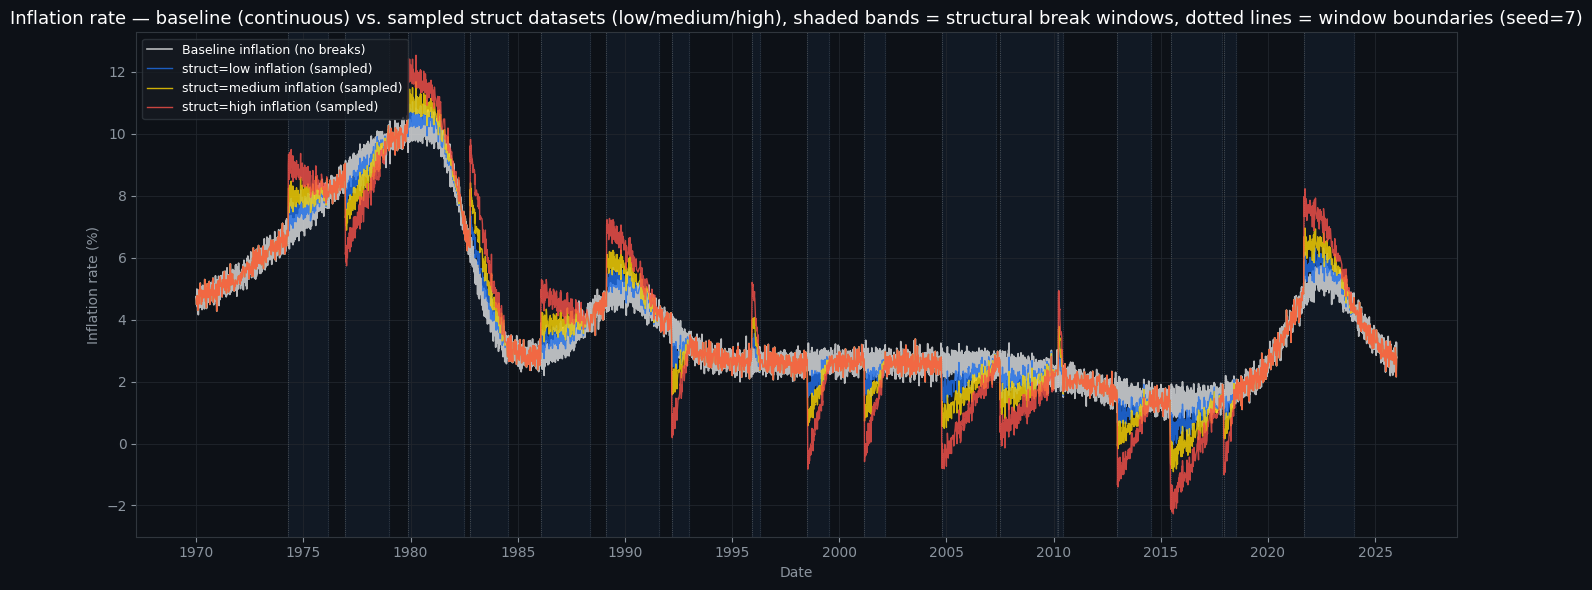

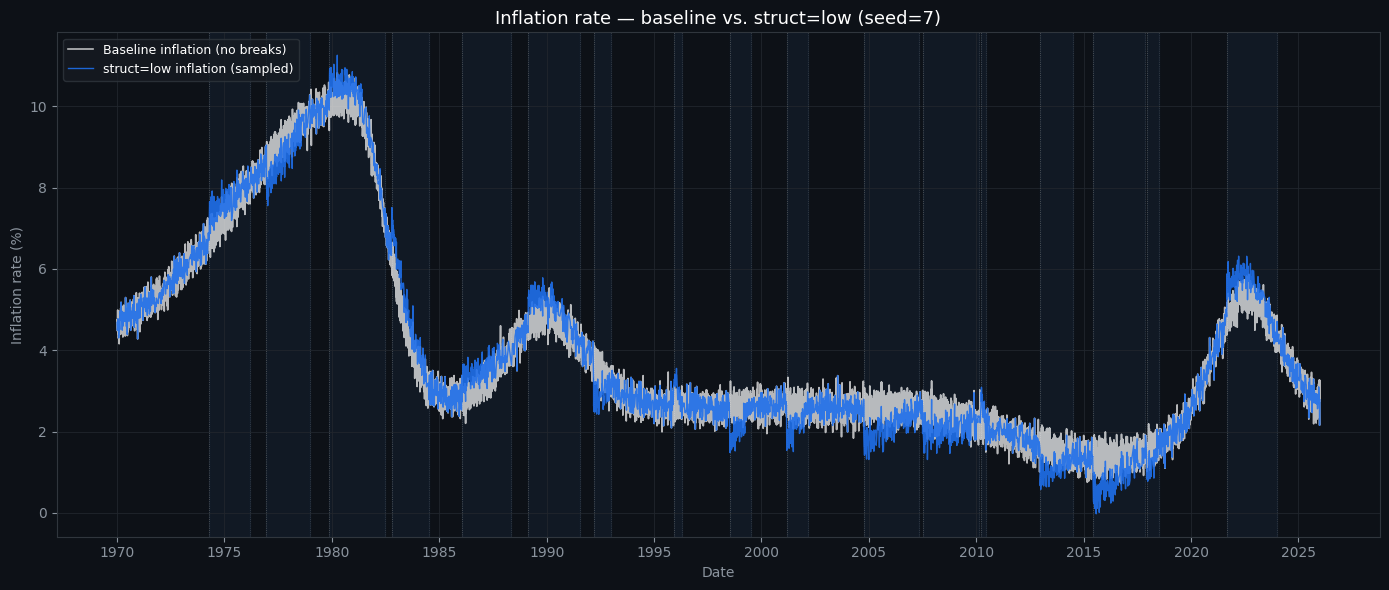

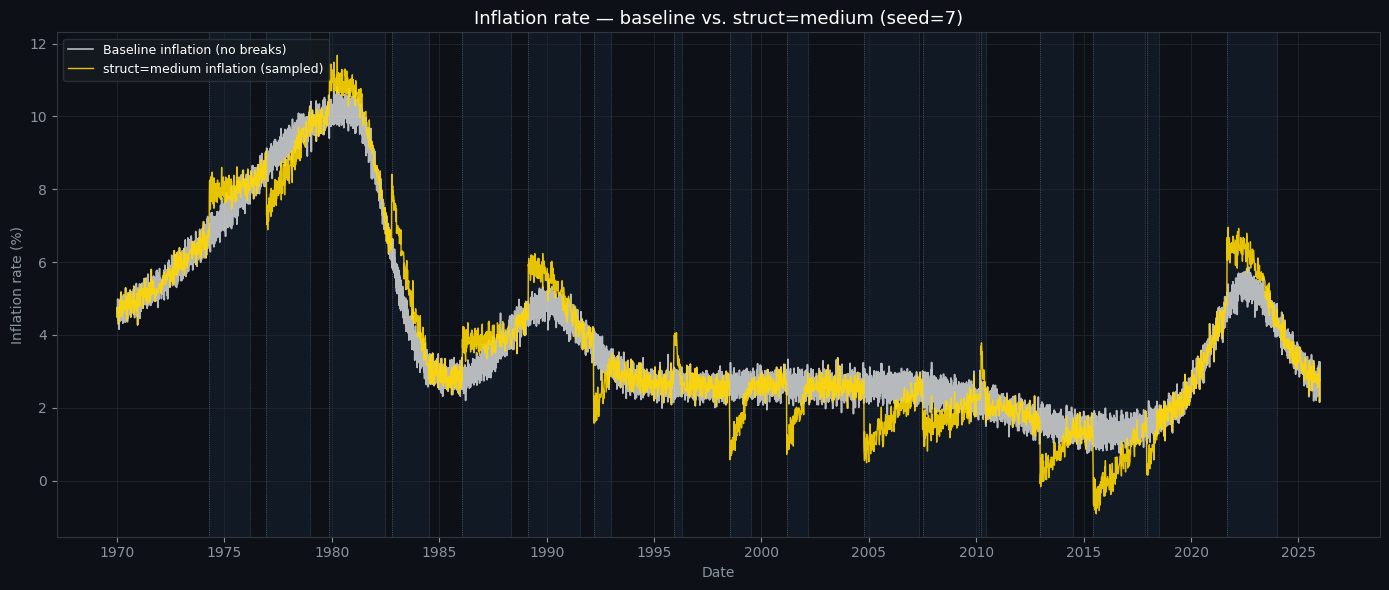

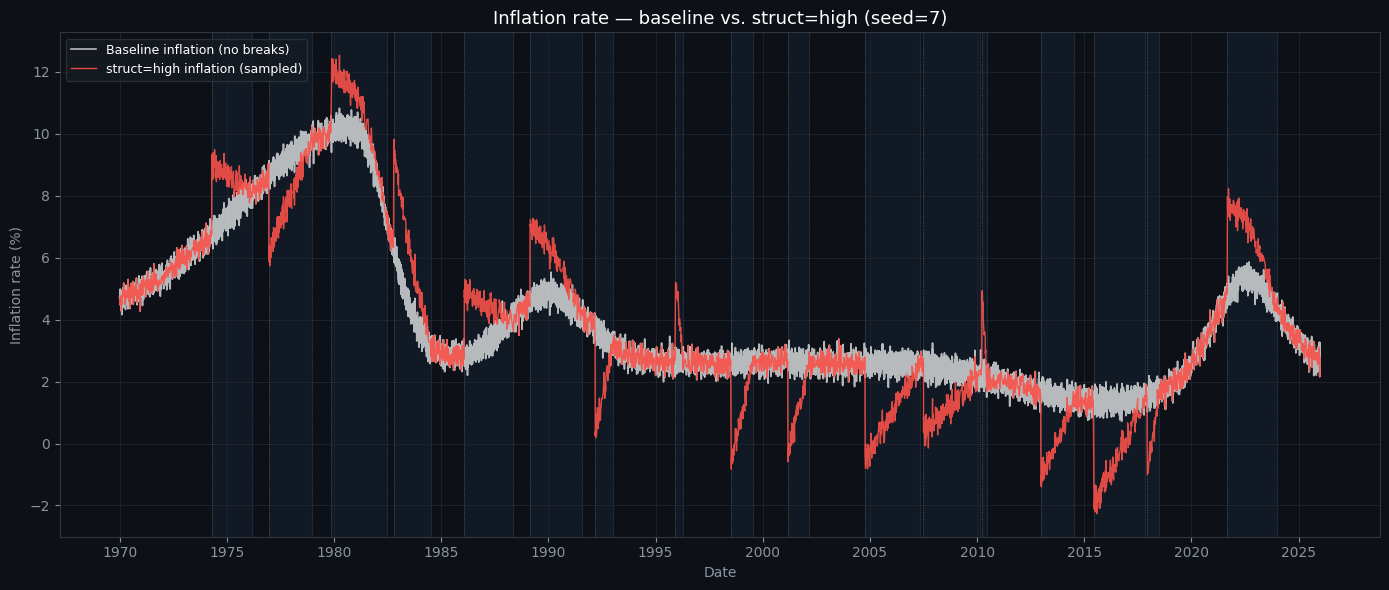

In [77]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#1f6feb", "medium": "#FFD700", "high": "#f85149"}

# ── Load the baseline series (full, continuous, no breaks) ─────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# ── Load the actual sampled struct datasets directly from disk ─────
# (these are the sparse, 5000-row SAMPLED files, not the full
# simulation -- sorted by date so the line connects points
# chronologically, not in obs_id order)
struct_data = {}
for cat in ("low", "medium", "high"):
    df = pd.read_csv(f"../data/stock_prices/articles_inflation_unemployment_struct_{cat}_seed7.csv",
                     parse_dates=["date"])
    struct_data[cat] = df[df["inflation"] == 1][["date", "price_inflation"]].sort_values("date")

# Use the representative window structure from the low-struct run.
result_low = simulate(SEED, "low")
struct_windows = result_low["inside_windows"]
struct_start_dates = [DATES[start_i] for start_i, end_i in struct_windows]
struct_end_dates   = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in struct_windows]


def add_break_shading(ax):
    for start_date, end_date in zip(struct_start_dates, struct_end_dates):
        ax.axvspan(start_date, end_date, color="#58a6ff", alpha=0.06, zorder=0)
        ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
        ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)


def style_axis(ax):
    ax.set_facecolor("#0d1117")
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(color="#21262d", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# ══════════════════════════════════════════════════════════════════
# Plot 1: ALL categories together, baseline inflation + struct low/medium/high
# ══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
style_axis(ax)
add_break_shading(ax)

ax.plot(baseline["date"], baseline["inflation_price"],
        color="white", lw=1.2, alpha=0.7, label="Baseline inflation (no breaks)", zorder=2)
for cat in ("low", "medium", "high"):
    ax.plot(struct_data[cat]["date"], struct_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.8, label=f"struct={cat} inflation (sampled)",
            zorder=3)

ax.set_title("Inflation rate — baseline (continuous) vs. sampled struct datasets (low/medium/high), "
             "shaded bands = structural break windows, dotted lines = window boundaries (seed=7)",
             color="white", fontsize=13)
ax.set_ylabel("Inflation rate (%)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
          labelcolor="white", fontsize=9)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════
# Plots 2-4: one separate plot per magnitude category
# ══════════════════════════════════════════════════════════════════
for cat in ("low", "medium", "high"):
    fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
    style_axis(ax)
    add_break_shading(ax)

    ax.plot(baseline["date"], baseline["inflation_price"],
            color="white", lw=1.2, alpha=0.7, label="Baseline inflation (no breaks)", zorder=2)
    ax.plot(struct_data[cat]["date"], struct_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.9, label=f"struct={cat} inflation (sampled)",
            zorder=3)

    ax.set_title(f"Inflation rate — baseline vs. struct={cat} (seed=7)",
                 color="white", fontsize=13)
    ax.set_ylabel("Inflation rate (%)", color="#8b949e")
    ax.set_xlabel("Date", color="#8b949e")
    ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
              labelcolor="white", fontsize=9)

    plt.tight_layout()
    plt.show()

### 5.8.2 Different var magnitudes

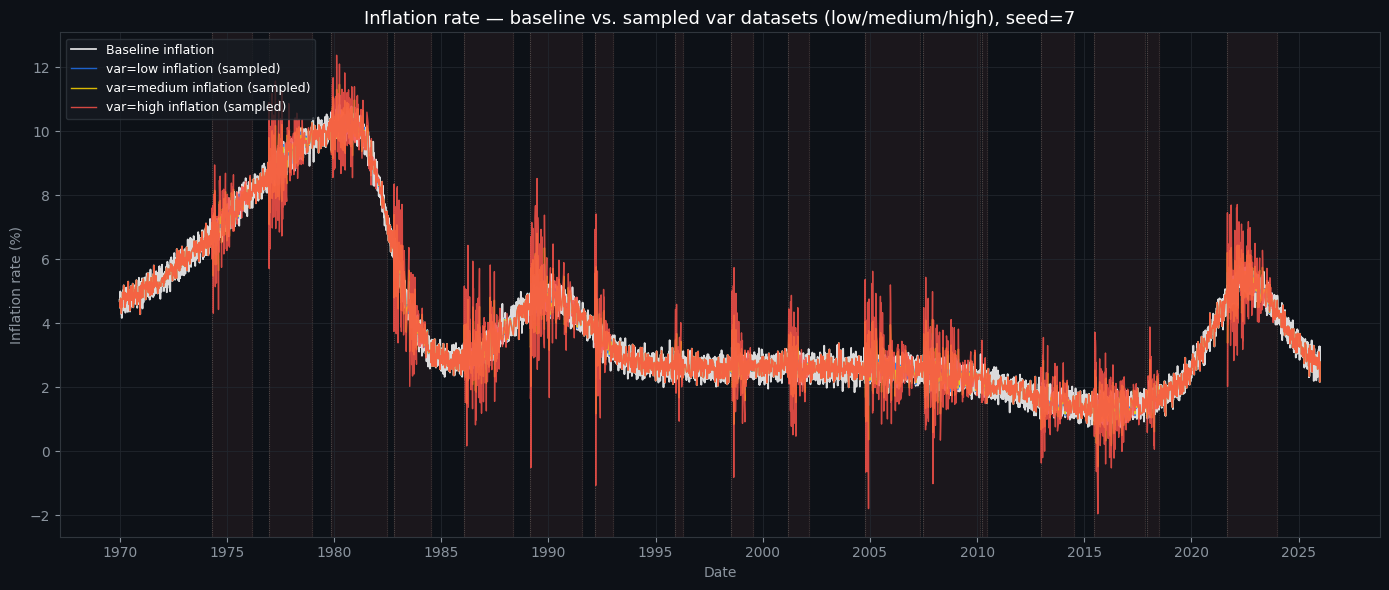

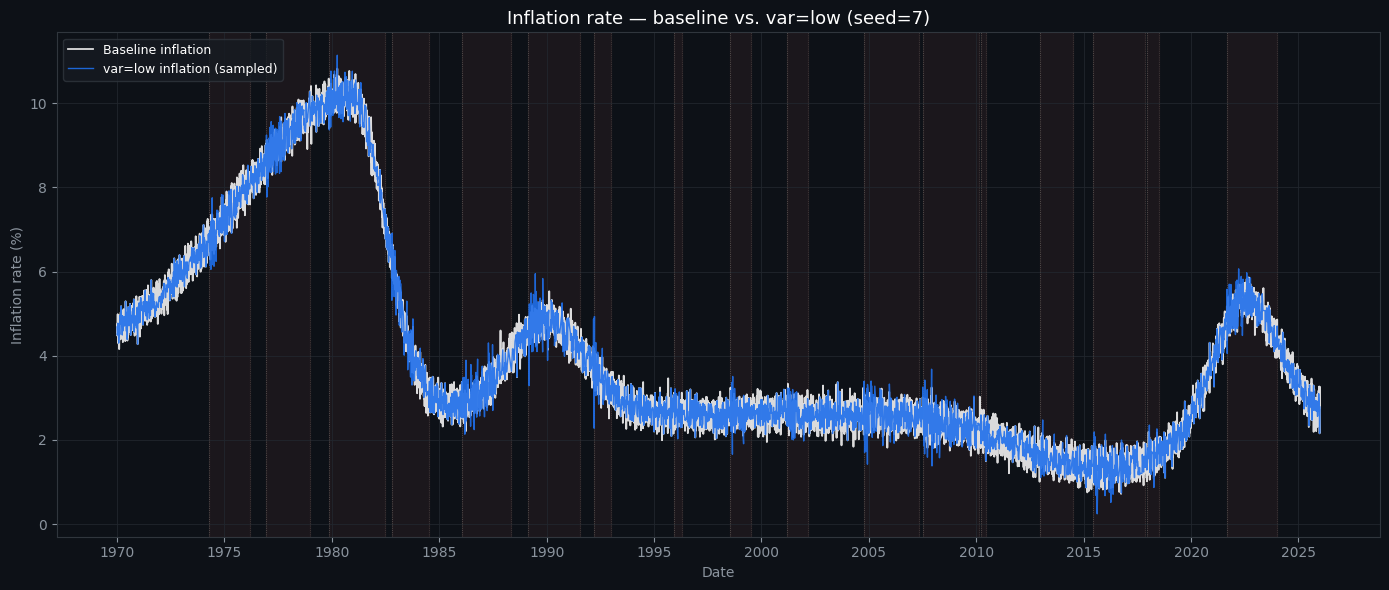

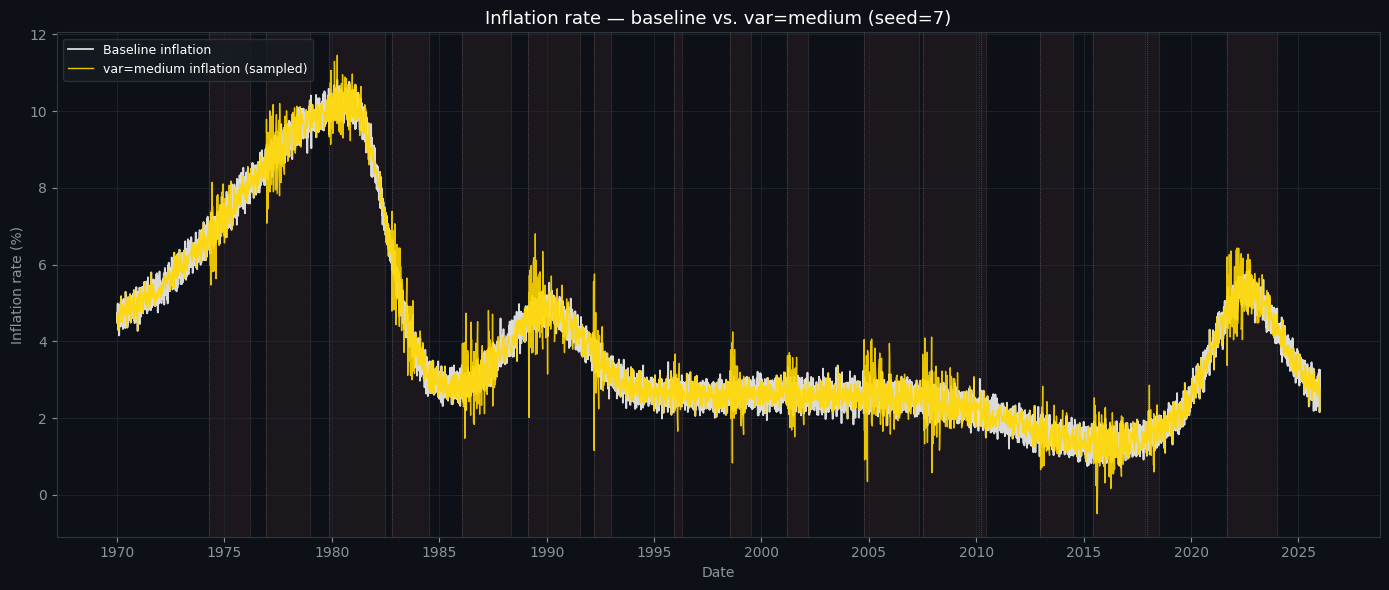

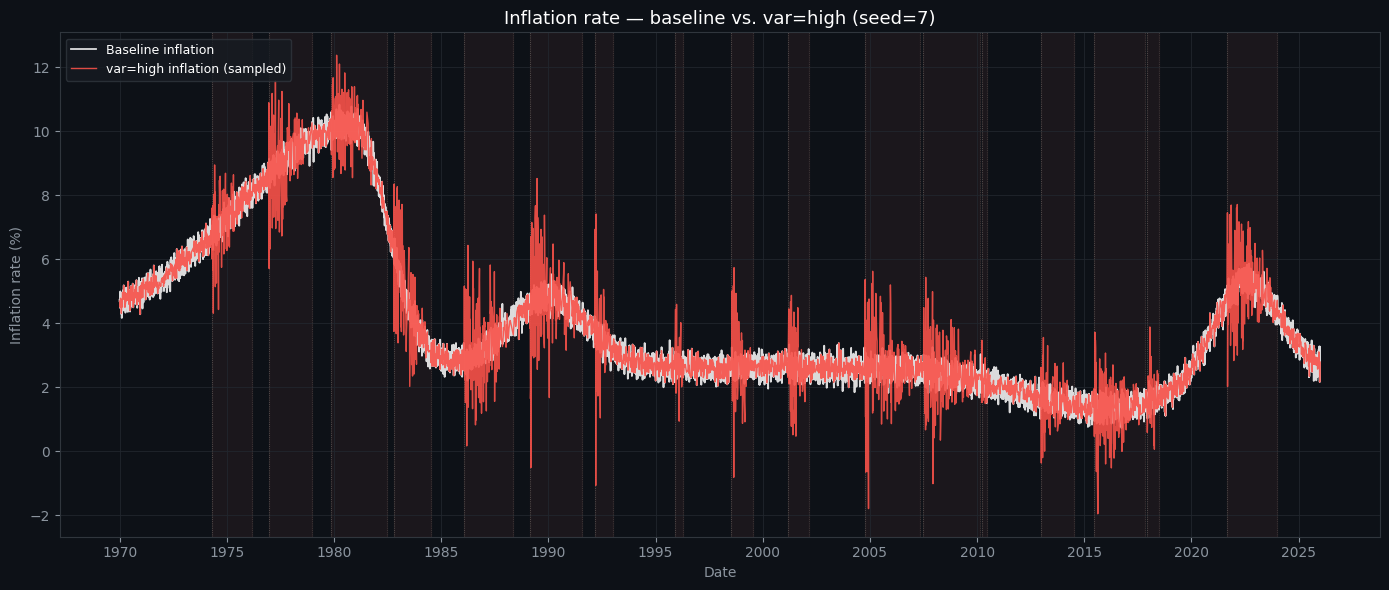

In [78]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#1f6feb", "medium": "#FFD700", "high": "#f85149"}

# ── Load the baseline series (full, continuous, no breaks) ─────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# ── Load the actual sampled var datasets directly from disk ────────
var_data = {}
for cat in ("low", "medium", "high"):
    df = pd.read_csv(f"../data/stock_prices/articles_inflation_unemployment_var_{cat}_seed7.csv",
                     parse_dates=["date"])
    var_data[cat] = df[df["inflation"] == 1][["date", "price_inflation"]].sort_values("date")

# ── Spike window structure (identical across categories) ────────────
result_low = simulate(SEED, "low")
spike_windows = result_low["inside_windows"]
spike_start_dates = [DATES[start_i] for start_i, end_i in spike_windows]
spike_end_dates   = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in spike_windows]


def add_spike_shading(ax):
    for start_date, end_date in zip(spike_start_dates, spike_end_dates):
        ax.axvspan(start_date, end_date, color="#ff7b72", alpha=0.06, zorder=0)
        ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
        ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)


def style_axis(ax):
    ax.set_facecolor("#0d1117")
    ax.tick_params(colors="#8b949e")
    for sp in ax.spines.values():
        sp.set_edgecolor("#30363d")
    ax.grid(color="#21262d", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


# ══════════════════════════════════════════════════════════════════
# Plot 1: ALL categories together, baseline inflation + var low/medium/high
# ══════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
style_axis(ax)
add_spike_shading(ax)

ax.plot(baseline["date"], baseline["inflation_price"],
        color="white", lw=1.3, alpha=0.85, label="Baseline inflation", zorder=2)
for cat in ("low", "medium", "high"):
    ax.plot(var_data[cat]["date"], var_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.85, label=f"var={cat} inflation (sampled)",
            zorder=3)

ax.set_title("Inflation rate — baseline vs. sampled var datasets (low/medium/high), seed=7",
             color="white", fontsize=13)
ax.set_ylabel("Inflation rate (%)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
          labelcolor="white", fontsize=9)

plt.tight_layout()
plt.show()

# ══════════════════════════════════════════════════════════════════
# Plots 2-4: one separate plot per magnitude category
# ══════════════════════════════════════════════════════════════════
for cat in ("low", "medium", "high"):
    fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
    style_axis(ax)
    add_spike_shading(ax)

    ax.plot(baseline["date"], baseline["inflation_price"],
            color="white", lw=1.3, alpha=0.85, label="Baseline inflation", zorder=2)
    ax.plot(var_data[cat]["date"], var_data[cat]["price_inflation"],
            color=cat_colors[cat], lw=1.0, alpha=0.9, label=f"var={cat} inflation (sampled)",
            zorder=3)

    ax.set_title(f"Inflation rate — baseline vs. var={cat} (seed=7)",
                 color="white", fontsize=13)
    ax.set_ylabel("Inflation rate (%)", color="#8b949e")
    ax.set_xlabel("Date", color="#8b949e")
    ax.legend(loc="upper left", facecolor="#161b22", edgecolor="#30363d",
              labelcolor="white", fontsize=9)

    plt.tight_layout()
    plt.show()

### 5.8.3 Different rhos

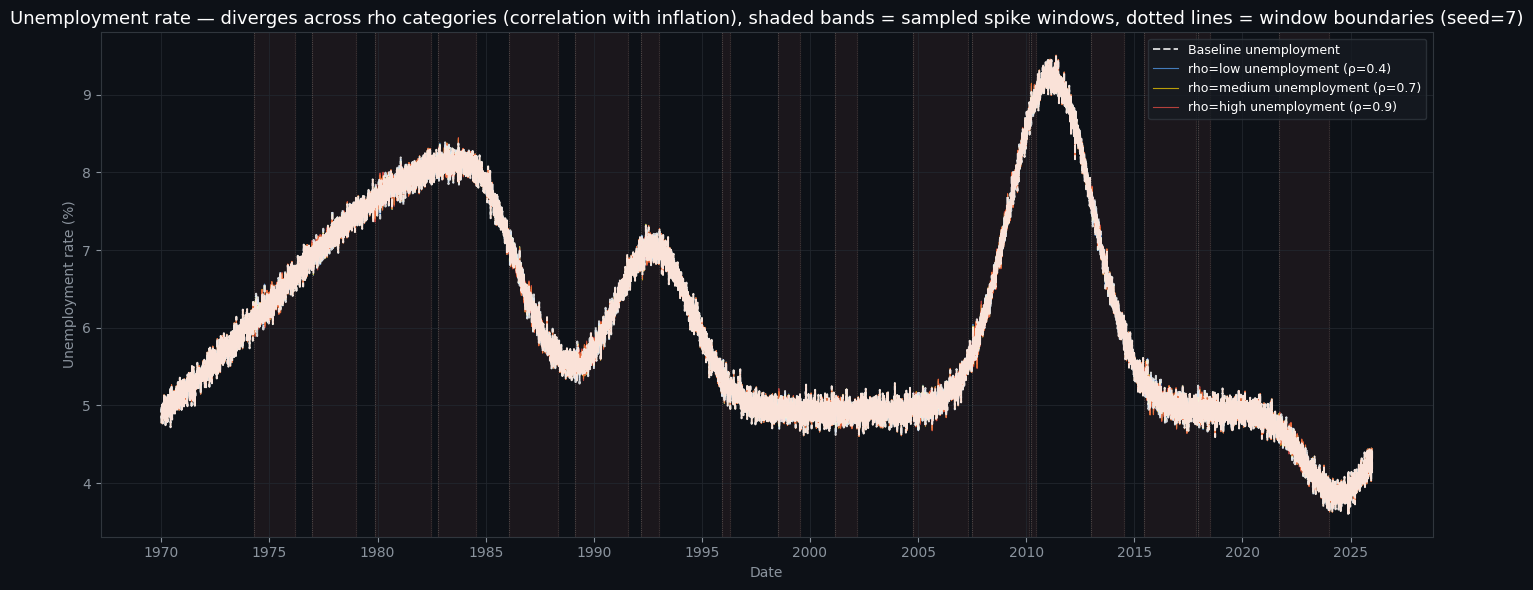

In [79]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

cat_colors = {"low": "#58a6ff", "medium": "#FFD700", "high": "#f85149"}

# ── Reconstruct full-resolution price paths for all three rho ──────
# categories (uses simulate() already defined in the rho script cell)
results_rho = {cat: simulate(SEED, cat) for cat in ("low", "medium", "high")}

# ── Load the baseline series for comparison ─────────────────────────
baseline = pd.read_csv("../data/stock_prices/baseline_inflation_unemployment_trial_seed7.csv",
                        parse_dates=["date"])

# Breakpoint bands come from the sampling cell above: use the exact
# inside_windows computed by simulate(SEED, "low").
result_low = simulate(SEED, "low")
spike_windows = result_low["inside_windows"]
spike_start_dates = [DATES[start_i] for start_i, end_i in spike_windows]
spike_end_dates = [DATES[min(end_i - 1, len(DATES) - 1)] for start_i, end_i in spike_windows]

fig, ax = plt.subplots(figsize=(14, 6), facecolor="#0d1117")
ax.set_facecolor("#0d1117")

# shaded bands and boundary markers for each spike window
for start_date, end_date in zip(spike_start_dates, spike_end_dates):
    ax.axvspan(start_date, end_date, color="#ff7b72", alpha=0.06, zorder=0)
    ax.axvline(start_date, color="#888780", ls=":", lw=0.6, alpha=0.6, zorder=1)
    ax.axvline(end_date, color="#888780", ls=":", lw=0.6, alpha=0.35, zorder=1)

# baseline drawn as a continuous line
ax.plot(baseline["date"], baseline["unemployment_price"],
         color="white", lw=1.4, ls="--", alpha=0.8, label="Baseline unemployment", zorder=5)

# rho-specific unemployment paths
for cat in ("low", "medium", "high"):
    rho_val = RHO_CATEGORIES[cat]
    ax.plot(DATES, results_rho[cat]["price_unemployment"],
            color=cat_colors[cat], lw=0.8, alpha=0.7,
            label=f"rho={cat} unemployment (ρ={rho_val})")

ax.set_title("Unemployment rate — diverges across rho categories (correlation with inflation), "
             "shaded bands = sampled spike windows, dotted lines = window boundaries (seed=7)",
             color="white", fontsize=13)
ax.set_ylabel("Unemployment rate (%)", color="#8b949e")
ax.set_xlabel("Date", color="#8b949e")
ax.legend(facecolor="#161b22", edgecolor="#30363d", labelcolor="white", fontsize=9)
ax.tick_params(colors="#8b949e")
for sp in ax.spines.values(): sp.set_edgecolor("#30363d")
ax.grid(color="#21262d", linewidth=0.6)
ax.set_axisbelow(True)
ax.xaxis.set_major_locator(mdates.YearLocator(5))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

## 5.9 Check the distribution of dates and labels for the sampled datasets

In [80]:
"""
Verifies that the "OUT" (label == 0) dates -- and their commodity-topic
labels (inflation/unemployment flags + commodity_topics string) -- in the
inflation_baseline dataset match those in each of the struct/var datasets
(low/medium/high). rho is intentionally excluded, and datasets are only
compared against inflation_baseline -- not against each other.

This should always hold by construction (same seed=7 break structure
for struct/var, same commodity_topic_seed_base = SEED + 4 for topic
sampling, and the baseline dataset's OUT rows were copied verbatim from
struct_low) -- this script exists to CONFIRM that, not to compute
anything new.

Run after the struct/var dataset-builder cells and the baseline inflation
cell have produced their CSVs on disk.
"""

import os
import pandas as pd

DATA_DIR = "../data/stock_prices"
SEED     = 7

DATASET_PATHS = {
    "struct_low":    f"articles_inflation_unemployment_struct_low_seed{SEED}.csv",
    "struct_medium": f"articles_inflation_unemployment_struct_medium_seed{SEED}.csv",
    "struct_high":   f"articles_inflation_unemployment_struct_high_seed{SEED}.csv",
    "var_low":       f"articles_inflation_unemployment_var_low_seed{SEED}.csv",
    "var_medium":    f"articles_inflation_unemployment_var_medium_seed{SEED}.csv",
    "var_high":      f"articles_inflation_unemployment_var_high_seed{SEED}.csv",
    "inflation_baseline": f"articles_all_commodities_baseline_seed{SEED}.csv",
}

# Only compare the baseline against struct/var (not against each other,
# and rho is excluded entirely).
REFERENCE_NAME = "inflation_baseline"
COMPARE_AGAINST = [
    "struct_low", "struct_medium", "struct_high",
    "var_low", "var_medium", "var_high",
]

LABEL_COLS = ["inflation", "unemployment", "commodity_topics"]

# ── 1. Load every dataset that actually exists on disk ───────────────
datasets = {}
for name, fname in DATASET_PATHS.items():
    path = os.path.join(DATA_DIR, fname)
    if not os.path.exists(path):
        print(f"[skip] {name}: file not found at {path}")
        continue
    df = pd.read_csv(path, parse_dates=["date"])
    if "label" not in df.columns:
        print(f"[skip] {name}: no 'label' column")
        continue
    datasets[name] = df

if len(datasets) < 2:
    raise RuntimeError("Need at least 2 datasets on disk to compare -- found "
                        f"{len(datasets)}.")

print(f"\nLoaded {len(datasets)} datasets: {list(datasets.keys())}\n")

# ── 2. Extract OUT rows (label == 0), indexed by date, for each dataset ──
out_by_dataset = {
    name: df[df["label"] == 0].set_index("date").sort_index()
    for name, df in datasets.items()
}

for name, out_df in out_by_dataset.items():
    print(f"{name:16s}: {len(out_df)} OUT rows")

# ── 3. Comparison: inflation_baseline's OUT dates/labels vs each struct/var
#    dataset's OUT dates/labels (not all-pairwise, and rho is excluded) ──
print("\n" + "=" * 70)
print(f"COMPARING '{REFERENCE_NAME}' AGAINST STRUCT/VAR DATASETS")
print("=" * 70)

if REFERENCE_NAME not in out_by_dataset:
    raise RuntimeError(f"Reference dataset '{REFERENCE_NAME}' not found on disk.")

comparisons = [
    (REFERENCE_NAME, name) for name in COMPARE_AGAINST if name in out_by_dataset
]
skipped = [name for name in COMPARE_AGAINST if name not in out_by_dataset]
if skipped:
    print(f"[skip] not found on disk, excluded from comparison: {skipped}")

all_ok = True
for name_a, name_b in comparisons:
    out_a = out_by_dataset[name_a]
    out_b = out_by_dataset[name_b]

    dates_a = set(out_a.index)
    dates_b = set(out_b.index)
    same_date_set = dates_a == dates_b

    missing_in_b = dates_a - dates_b
    missing_in_a = dates_b - dates_a

    # ── labels compared only on the shared dates ──────────────────
    shared_dates = sorted(dates_a & dates_b)
    label_mismatches = []
    if shared_dates:
        merged = out_a.loc[shared_dates, LABEL_COLS].join(
            out_b.loc[shared_dates, LABEL_COLS],
            lsuffix=f"_{name_a}", rsuffix=f"_{name_b}",
        )
        for col in LABEL_COLS:
            col_a, col_b = f"{col}_{name_a}", f"{col}_{name_b}"
            mism = merged[merged[col_a] != merged[col_b]]
            if len(mism) > 0:
                label_mismatches.append((col, len(mism)))

    status = "OK" if same_date_set and not label_mismatches else "MISMATCH"
    if status == "MISMATCH":
        all_ok = False

    print(f"\n[{status}] {name_a}  vs  {name_b}")
    print(f"  same OUT date set        : {same_date_set}")
    if not same_date_set:
        print(f"    dates in {name_a} but not {name_b}: {len(missing_in_b)}")
        print(f"    dates in {name_b} but not {name_a}: {len(missing_in_a)}")
    print(f"  shared dates compared     : {len(shared_dates)}")
    if label_mismatches:
        for col, n in label_mismatches:
            print(f"    mismatch in '{col}': {n} / {len(shared_dates)} dates differ")
    else:
        print(f"  labels match on all shared dates: True")

print("\n" + "=" * 70)
print(f"OVERALL RESULT: {'ALL DATASETS CONSISTENT ✅' if all_ok else 'MISMATCHES FOUND ❌'}")
print("=" * 70)


Loaded 7 datasets: ['struct_low', 'struct_medium', 'struct_high', 'var_low', 'var_medium', 'var_high', 'inflation_baseline']

struct_low      : 2500 OUT rows
struct_medium   : 2500 OUT rows
struct_high     : 2500 OUT rows
var_low         : 2500 OUT rows
var_medium      : 2500 OUT rows
var_high        : 2500 OUT rows
inflation_baseline: 2500 OUT rows

COMPARING 'inflation_baseline' AGAINST STRUCT/VAR DATASETS

[OK] inflation_baseline  vs  struct_low
  same OUT date set        : True
  shared dates compared     : 2500
  labels match on all shared dates: True

[OK] inflation_baseline  vs  struct_medium
  same OUT date set        : True
  shared dates compared     : 2500
  labels match on all shared dates: True

[OK] inflation_baseline  vs  struct_high
  same OUT date set        : True
  shared dates compared     : 2500
  labels match on all shared dates: True

[OK] inflation_baseline  vs  var_low
  same OUT date set        : True
  shared dates compared     : 2500
  labels match on all s

## 5.10 Check the distribution of dates and labels for the sampled datasets

Loaded 5000 total rows, 2500 IN rows, 2500 OUT rows.


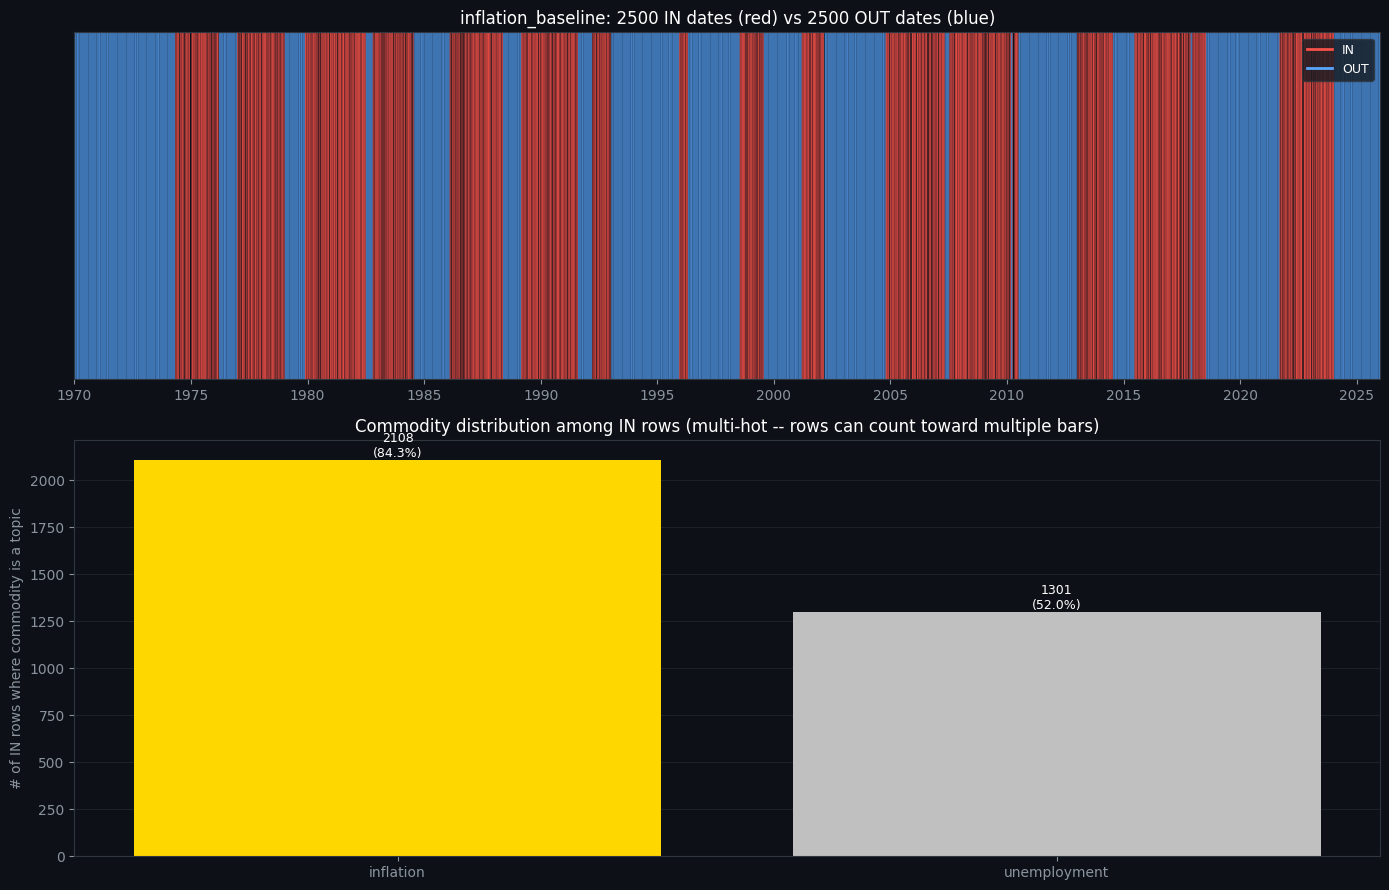


Full commodity_topics distribution (IN rows only):
commodity_topics
inflation                 1199
inflation,unemployment     909
unemployment               392
Name: count, dtype: int64


In [81]:
"""
Two diagnostic plots for the inflation_baseline dataset:

1. A timeline (1970-2025) with a vertical line at every sampled "IN"
   date (red) and every "OUT" date (blue), so you can visually confirm
   IN dates cluster inside break windows while OUT dates fill the rest.
2. A bar chart of how often each commodity (inflation/unemployment)
   appears as a topic among the IN rows specifically.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "../data/stock_prices"
SEED     = 7

PATH = os.path.join(DATA_DIR, f"articles_all_commodities_baseline_seed{SEED}.csv")
df = pd.read_csv(PATH, parse_dates=["date"])

in_rows  = df[df["label"] == 1].sort_values("date")
out_rows = df[df["label"] == 0].sort_values("date")
print(f"Loaded {len(df)} total rows, {len(in_rows)} IN rows, {len(out_rows)} OUT rows.")

# ── Plot 1: IN dates and OUT dates as vertical lines, different colors ──
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 9), facecolor="#0d1117",
    gridspec_kw={"height_ratios": [1, 1.2]},
)

ax1.set_facecolor("#0d1117")
for d in out_rows["date"]:
    ax1.axvline(d, color="#58a6ff", lw=0.5, alpha=0.35)
for d in in_rows["date"]:
    ax1.axvline(d, color="#f85149", lw=0.5, alpha=0.35)

ax1.set_xlim(df["date"].min(), df["date"].max())
ax1.set_yticks([])
ax1.tick_params(colors="#8b949e")
for sp in ax1.spines.values():
    sp.set_edgecolor("#30363d")
ax1.xaxis.set_major_locator(mdates.YearLocator(5))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.set_title(
    f"inflation_baseline: {len(in_rows)} IN dates (red) vs {len(out_rows)} OUT dates (blue)",
    color="white", fontsize=12,
)
ax1.legend(
    handles=[
        plt.Line2D([0], [0], color="#f85149", lw=2, label="IN"),
        plt.Line2D([0], [0], color="#58a6ff", lw=2, label="OUT"),
    ],
    facecolor="#161b22", edgecolor="#30363d", labelcolor="white",
    loc="upper right", fontsize=9,
)

# ── Plot 2: commodity distribution among IN rows ──────────────────────
commodity_colors = {
    "inflation": "#FFD700", "unemployment": "#C0C0C0",
}
counts = {c: int(in_rows[c].sum()) for c in commodity_colors}

ax2.set_facecolor("#0d1117")
bars = ax2.bar(
    counts.keys(), counts.values(),
    color=[commodity_colors[c] for c in counts],
)
for bar, c in zip(bars, counts):
    ax2.text(
        bar.get_x() + bar.get_width() / 2, bar.get_height(),
        f"{counts[c]}\n({counts[c] / len(in_rows):.1%})",
        ha="center", va="bottom", color="white", fontsize=9,
    )

ax2.tick_params(colors="#8b949e")
for sp in ax2.spines.values():
    sp.set_edgecolor("#30363d")
ax2.grid(color="#21262d", linewidth=0.6, axis="y")
ax2.set_axisbelow(True)
ax2.set_ylabel("# of IN rows where commodity is a topic", color="#8b949e")
ax2.set_title(
    "Commodity distribution among IN rows (multi-hot -- rows can count toward multiple bars)",
    color="white", fontsize=12,
)

plt.tight_layout()
plt.show()

# ── Also print the full commodity_topics breakdown for reference ────
print("\nFull commodity_topics distribution (IN rows only):")
print(in_rows["commodity_topics"].value_counts())